# **Dataset Sign Languages SIBI**

---

## **Nama Sekolah: SMKN 1 Surabaya**

### **Nama Peserta:**

#### - **Davino Edric Faturrahman** 
#### - **Muhammad Shofian Najib**

### **No. Peserta: 23**

---

## **Tema: Membuat model prediksi bahasa isyarat berdasarkan kordinat yang diberikan menggunakan model KNN**

---

### **Narasi bisnis: Diberikan dataset mengenai bahasa isyarat serta artinya, dan ditugaskan untuk membuat model KNN yang dapat mendeteksi huruf yang dimaksud untuk mempermudah komunikasi antara pelanggan tunarungu dengan pelayan bisnis FnB**

---

# **A. Import Library & EDA**

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from matplotlib.lines import Line2D

## **A.1 Menggabung data train dan test untuk mengeksplor seluruh dataset**

In [2]:
train = pd.read_csv("Datafull train.csv", sep=';')
test = pd.read_csv('Datafull terakhir test.csv',sep=';')
df = pd.concat((train,test))
df.head()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
0,449.894,638.530,329.537,588.029,262.366,475.709,253.967,343.421,247.663,236.477,...,475.346,591.398,426.475,592.339,341.419,548.671,413.658,541.039,454.239,NaN
1,459.426,638.641,347.614,599.550,273.522,486.969,262.374,354.810,248.102,248.011,...,471.021,587.605,425.540,598.047,337.165,559.660,410.858,548.164,455.238,A
2,444.194,659.268,326.598,616.910,253.226,497.914,243.082,361.876,239.491,259.676,...,476.613,560.803,418.030,567.584,346.090,533.656,416.844,524.283,450.811,A
3,443.780,650.429,324.970,607.825,252.818,487.201,244.345,356.561,243.655,256.638,...,473.187,573.173,418.568,580.205,339.026,541.187,411.295,528.062,445.777,A
4,452.860,638.769,340.436,595.407,272.323,487.497,254.365,357.569,231.482,241.993,...,463.566,577.341,425.073,581.486,337.553,551.375,410.228,546.574,449.936,A


## **A.2 Membaca info data**

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41062 entries, 0 to 8212
Data columns (total 43 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0x      41062 non-null  float64
 1   0y      41062 non-null  float64
 2   1x      41062 non-null  float64
 3   1y      41062 non-null  float64
 4   2x      41062 non-null  float64
 5   2y      41062 non-null  float64
 6   3x      41062 non-null  float64
 7   3y      41062 non-null  float64
 8   4x      41062 non-null  float64
 9   4y      41062 non-null  float64
 10  5x      41062 non-null  float64
 11  5y      41062 non-null  float64
 12  6x      41062 non-null  float64
 13  6y      41062 non-null  float64
 14  7x      41062 non-null  float64
 15  7y      41062 non-null  float64
 16  8x      41062 non-null  float64
 17  8y      41062 non-null  float64
 18  9x      41062 non-null  float64
 19  9y      41062 non-null  float64
 20  10x     41062 non-null  float64
 21  10y     41062 non-null  float64
 22  11x 

**Dataset ini memiliki 42 fitur numerik kontinu dan 1 kolom label**

## **A.3 Statistik Deskriptif**

In [4]:
df.describe()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16x,16y,17x,17y,18x,18y,19x,19y,20x,20y
count,41062.000000,41062.000000,41062.000000,41062.000000,41062.000000,41062.000000,41062.000000,41062.000000,41062.000000,41062.000000,...,41055.000000,41059.000000,41055.000000,41060.000000,41061.000000,41061.000000,41062.000000,41062.000000,41062.000000,41062.000000
mean,452.469772,475.651859,427.692687,444.939198,423.508430,400.123654,438.994497,362.070023,452.806936,338.605840,...,499.493952,364.279159,522.228919,387.930068,536.209251,353.842354,525.936680,358.550826,517.669116,365.576406
std,33.319934,53.207547,54.540801,52.937577,80.477874,69.240689,101.466443,93.631533,120.927141,114.755375,...,102.485935,119.070545,66.634470,74.081307,87.572870,96.124794,93.227186,102.660775,97.014185,110.147608
min,26.970000,0.000000,0.000000,0.000000,-33.654000,0.000000,-72.274000,0.000000,-96.256000,0.000000,...,-139.906000,7.845000,-49.063000,54.555000,-83.522000,35.426000,-92.401000,39.292000,-98.609000,45.460000
25%,441.033750,453.312750,391.625000,410.740500,365.176250,352.487250,368.095250,300.434750,374.355500,264.112500,...,452.722000,303.877500,493.603500,340.611750,495.062000,290.748000,483.905250,291.922500,475.391000,296.428500
50%,450.213500,468.580000,413.454500,436.152000,407.711000,383.586000,430.271000,337.717000,452.080500,310.040500,...,489.728000,365.239000,529.479000,371.545000,545.333000,329.810000,531.478500,341.755000,517.610000,359.665000
75%,461.001000,491.780250,463.027000,471.671750,480.023000,432.953750,506.630750,396.691000,530.957750,375.666000,...,544.110500,409.718000,560.217500,424.047000,590.079000,392.099000,577.942750,400.238750,568.648000,414.180000
max,846.956000,964.173000,822.414000,861.044000,835.397000,828.416000,854.552000,837.067000,898.948000,840.879000,...,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000


## **A.4 Mengecek NaN**

In [5]:
df.isna().sum()

0x       0
0y       0
1x       0
1y       0
2x       0
2y       0
3x       0
3y       0
4x       0
4y       0
5x       0
5y       0
6x       0
6y       0
7x       0
7y       0
8x       0
8y       0
9x       0
9y       0
10x      0
10y      0
11x      0
11y      0
12x      0
12y      0
13x      1
13y      0
14x      3
14y      3
15x      4
15y     10
16x      7
16y      3
17x      7
17y      2
18x      1
18y      1
19x      0
19y      0
20x      0
20y      0
char    43
dtype: int64

In [6]:
char_nan = df[df['char'].isna()].sort_index()
char_nan

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
0,449.894,638.530,329.537,588.029,262.366,475.709,253.967,343.421,247.663,236.477,...,475.346,591.398,426.475,592.339,341.419,548.671,413.658,541.039,454.239,NaN
0,449.429,643.857,327.271,587.170,265.731,484.233,246.689,362.602,231.657,252.290,...,480.806,582.295,427.375,587.343,339.388,547.296,415.208,536.242,454.387,NaN
445,445.804,520.937,391.107,457.721,376.529,385.601,409.115,329.468,439.100,320.926,...,189.812,515.830,385.855,529.530,332.028,537.024,296.671,547.011,258.928,NaN
741,437.668,494.603,439.646,446.746,435.675,399.259,430.962,358.831,426.013,335.180,...,271.383,402.350,401.851,349.336,347.184,307.780,318.423,278.834,300.686,NaN
1165,457.613,451.963,521.013,484.663,580.531,472.083,633.189,453.732,654.880,424.080,...,334.642,552.604,373.276,603.398,352.902,618.135,337.626,617.993,315.932,NaN
1554,432.491,411.617,484.594,392.321,519.189,362.543,554.455,334.653,580.503,319.995,...,246.797,506.323,329.826,560.307,311.412,584.848,316.220,600.086,319.076,NaN
1741,448.485,468.500,412.110,406.789,416.611,344.840,437.034,291.100,466.389,265.353,...,192.246,576.613,381.869,609.780,342.402,634.369,314.328,658.548,285.898,NaN
2153,472.970,483.326,435.392,460.567,396.888,426.136,364.065,407.458,328.271,383.243,...,432.669,404.437,367.368,325.138,384.966,315.934,419.091,314.130,438.914,NaN
2770,512.121,440.786,540.150,497.330,607.836,528.272,688.973,546.188,766.986,545.079,...,343.801,664.320,325.523,734.110,305.059,773.983,323.198,798.989,347.832,NaN
2781,467.427,443.829,410.892,393.161,367.369,345.187,368.513,280.857,380.744,250.486,...,348.464,535.832,326.825,556.610,257.977,554.867,242.901,561.008,238.126,NaN


**`Insight: Index yang berbeda dari kolom nan ini menunjukkan bahwa ini bukan dari kelas yang sama, melainkan sebuah kehilangan data asli`**

## **A.5 Pengecekan kolom Char (Class minoritas dan Mayoritas, huruf yang mungkin hilang, dan NaN di di kolom Char)**

In [7]:
df['char'].unique()

array([nan, 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M',
       'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y'],
      dtype=object)

In [8]:
df['char'].value_counts().sort_index()

char
A    1639
B    1658
C    1680
D    1682
E    1681
F    1699
G    1646
H    1695
I    1528
K    1660
L    1647
M    1647
N    1693
O    1638
P    2096
Q    1857
R    1856
S    1628
T    1688
U    1703
V    1768
W    1747
X    1730
Y    1753
Name: count, dtype: int64

In [9]:
char_nan = df[df['char'].isna()]
char_nan.describe()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16x,16y,17x,17y,18x,18y,19x,19y,20x,20y
count,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,...,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000,43.000000
mean,450.134372,486.544442,418.904047,453.072791,412.969860,405.182465,430.801837,361.488302,448.305558,331.721442,...,515.413140,380.930953,532.260326,393.544628,549.298558,358.852070,540.948953,367.807140,535.503163,374.961791
std,41.064400,75.796340,57.619417,72.261241,85.787198,82.281758,109.436512,103.982418,129.841505,123.629312,...,109.594816,121.746820,64.551127,89.743677,90.769530,105.818966,101.357538,112.334359,108.776327,122.001774
min,218.052000,349.026000,272.241000,360.504000,262.366000,295.190000,244.619000,211.835000,190.663000,142.024000,...,273.735000,56.963000,320.836000,283.041000,299.964000,208.267000,265.427000,162.737000,255.305000,120.881000
25%,441.796500,451.553000,379.907000,405.560000,352.227000,346.173000,356.221000,298.161500,352.748500,250.833500,...,469.185000,339.643000,510.316500,332.087000,522.688500,302.285500,511.046000,312.998000,494.427000,314.504500
50%,450.990000,468.562000,412.110000,440.556000,403.803000,388.754000,430.962000,336.734000,439.100000,301.380000,...,508.508000,368.664000,541.371000,378.635000,562.962000,339.388000,547.296000,344.860000,536.242000,368.415000
75%,464.773500,495.725500,442.373500,472.843000,463.795000,452.822000,502.210500,400.824500,523.149500,377.927500,...,562.146500,409.008500,575.573500,416.507500,608.031500,377.228500,606.747000,394.265500,602.307000,413.415000
max,512.121000,743.283000,545.085000,757.496000,607.836000,771.879000,688.973000,780.926000,766.986000,785.376000,...,824.136000,780.739000,664.320000,771.950000,734.110000,781.123000,773.983000,779.531000,798.989000,775.407000


**Insight : Huruf J dan Z tidak ada di dalam dataset, namun ada nan pada kolom char berjumlah 43 kolom, jika ini merupakan value untuk J dan Z maka terlalu sedikit. Kelas Mayoritas merupakan huruf P,Q,R, Sementara kelas Minoritas merupakan huruf I**

## **A.6 Mengecek data duplikat**

**Mengecek jumlah data duplikat**

In [10]:
df.duplicated().sum()

np.int64(28)

**Membuat dataframe khusus untuk data duplikat**

In [11]:
duplicated = df[df.duplicated()].sort_index()
duplicated

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
4871,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
4872,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
4873,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
4874,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
4875,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
19376,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
19377,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
19378,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
19379,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P
19380,456.072,455.709,469.294,485.024,501.082,508.965,536.722,535.553,568.748,559.009,...,619.265,545.839,526.871,563.574,573.888,567.394,595.932,569.647,608.639,P


**Membuat dataframe dimana duplikat di drop, dan mengecek statistik deksriptif huruf P untuk dibandingkan dengan baris di dataframe asli**

In [12]:
df_n_dupe = df.drop_duplicates()
df_n_dupe_p = df_n_dupe[df_n_dupe['char'] == 'P']
df_n_dupe.describe()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16x,16y,17x,17y,18x,18y,19x,19y,20x,20y
count,41034.000000,41034.000000,41034.000000,41034.000000,41034.000000,41034.000000,41034.000000,41034.000000,41034.000000,41034.000000,...,41027.000000,41031.000000,41027.000000,41032.000000,41033.000000,41033.000000,41034.000000,41034.000000,41034.000000,41034.000000
mean,452.467314,475.665467,427.664300,444.911846,423.455497,400.049385,438.927812,361.951645,452.727822,338.455445,...,499.431119,364.105154,522.212805,387.835255,536.190577,353.692199,525.908391,358.388846,517.633649,365.410549
std,33.331167,53.223146,54.548575,52.945275,80.479802,69.205890,101.468925,93.553702,120.930447,114.649951,...,102.492665,118.924640,66.654349,74.017583,87.599826,95.985505,93.252696,102.508284,97.037775,110.001966
min,26.970000,0.000000,0.000000,0.000000,-33.654000,0.000000,-72.274000,0.000000,-96.256000,0.000000,...,-139.906000,7.845000,-49.063000,54.555000,-83.522000,35.426000,-92.401000,39.292000,-98.609000,45.460000
25%,441.027250,453.300250,391.603750,410.728000,365.149750,352.467750,368.063000,300.416500,374.267250,264.075250,...,452.695500,303.802500,493.584000,340.594500,494.968000,290.733000,483.861250,291.893250,475.349750,296.344750
50%,450.208000,468.602500,413.424500,436.111000,407.629500,383.547500,430.179000,337.666000,451.980000,309.966500,...,489.679000,365.158000,529.447000,371.524000,545.257000,329.772000,531.430000,341.698500,517.568500,359.602000
75%,461.013750,491.834250,462.940750,471.573750,479.827750,432.839250,506.381000,396.579750,530.819750,375.502000,...,543.992500,409.565500,560.239500,423.847000,590.094000,391.872000,577.991000,400.045750,568.510000,414.033500
max,846.956000,964.173000,822.414000,861.044000,835.397000,828.416000,854.552000,837.067000,898.948000,840.879000,...,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000


**Statistik Deskriptif huruf P untuk dibandingkan dengan dataframe dp_n_dupe_p**

In [13]:
p_class = df[df['char'] == 'P']
p_class.describe()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16x,16y,17x,17y,18x,18y,19x,19y,20x,20y
count,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,...,2095.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000,2096.000000
mean,465.299041,421.419012,477.448385,457.673093,503.348985,494.593289,524.507748,533.764585,543.125821,567.082950,...,527.215825,592.246585,509.291924,501.320471,517.615489,550.869509,518.053302,569.835116,516.990007,579.650944
std,61.904598,76.732141,66.662879,72.257711,69.880776,70.326691,72.983102,70.171712,78.222300,72.653176,...,89.354230,78.324764,81.999184,75.048819,88.197855,71.948138,87.824061,72.451567,86.411924,75.807847
min,249.558000,117.522000,291.321000,136.081000,304.659000,150.252000,300.324000,176.103000,298.375000,199.191000,...,296.669000,257.781000,294.031000,203.420000,286.509000,219.200000,290.427000,230.434000,294.517000,237.752000
25%,437.717500,411.045750,443.562000,442.237000,463.395500,475.078250,481.153000,517.638750,496.360500,548.160750,...,471.774000,547.521500,461.556000,482.475750,462.428250,527.563000,461.510750,543.049000,460.090750,538.814250
50%,448.992000,442.170000,468.021500,476.561000,495.751500,510.747500,515.473000,547.998500,532.761000,582.063500,...,509.637000,606.185000,497.935500,520.052000,505.682000,568.327500,503.249000,579.133000,499.942500,590.682000
75%,462.522000,456.913250,493.216000,495.625500,526.622500,535.099500,549.400250,575.785000,570.634000,610.997750,...,569.745500,643.857250,533.233500,544.247500,552.311500,596.078000,553.790000,620.027250,555.558000,635.397250
max,846.956000,846.589000,822.414000,814.815000,835.397000,828.416000,854.552000,837.067000,870.961000,840.879000,...,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,881.230000,833.416000


**Insight : Semua data duplikat memiliki label P, dan dataframe dengan duplikat memiliki mean yang lebih tinggi untuk banyak fitur**

## **A.6 Histogram dan Boxplot**

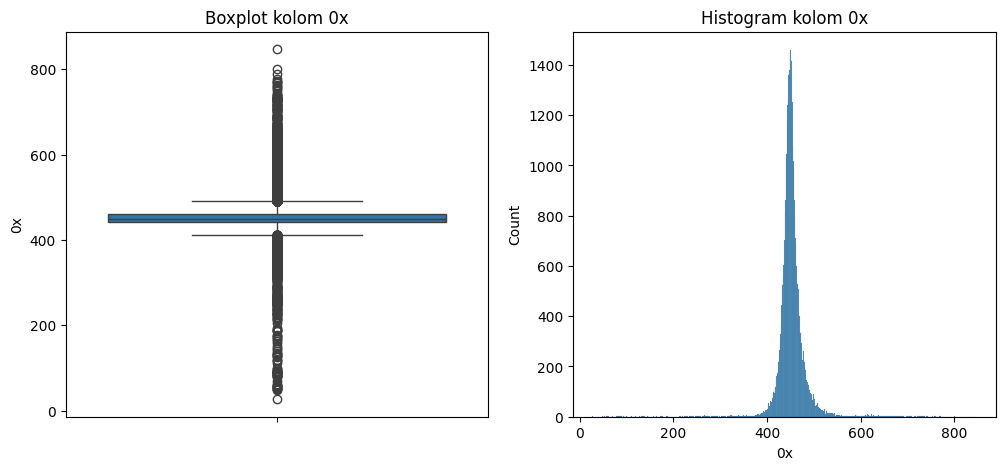

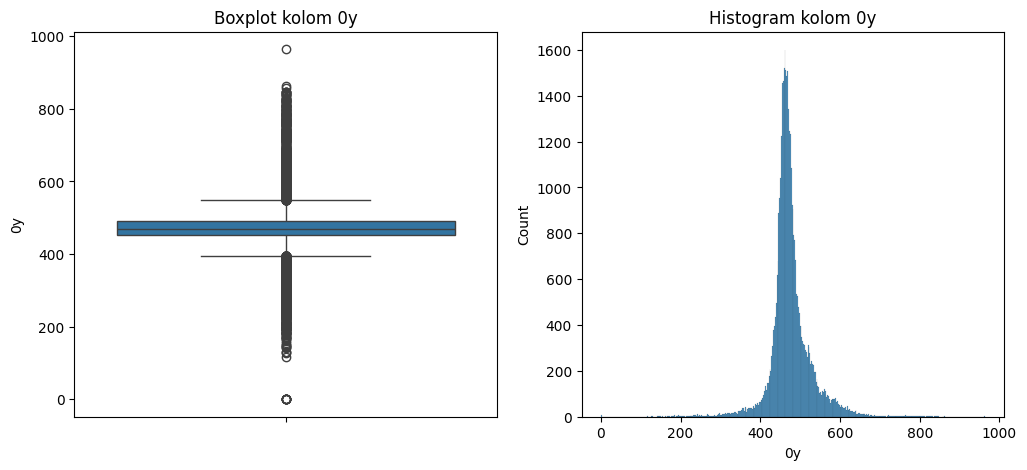

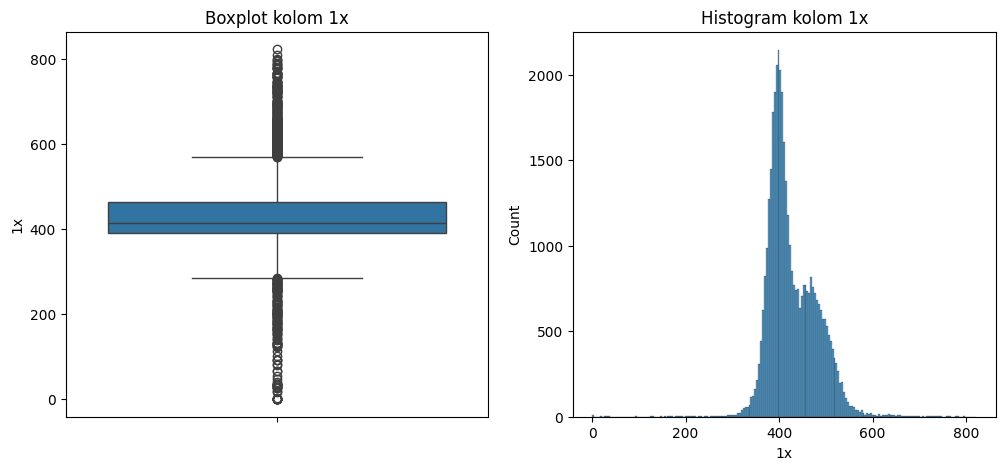

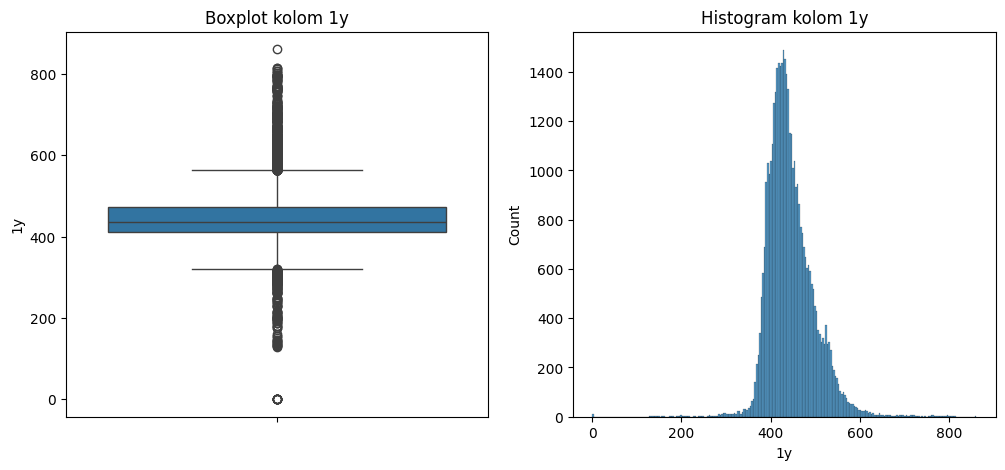

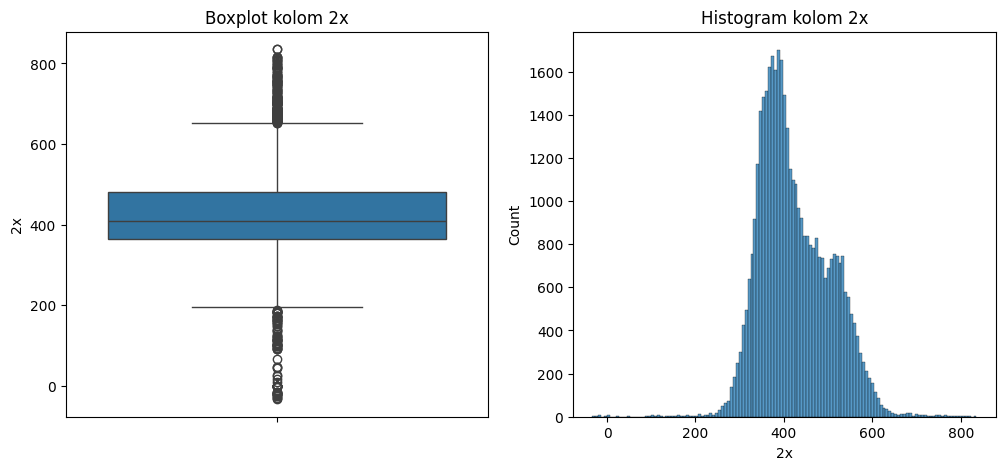

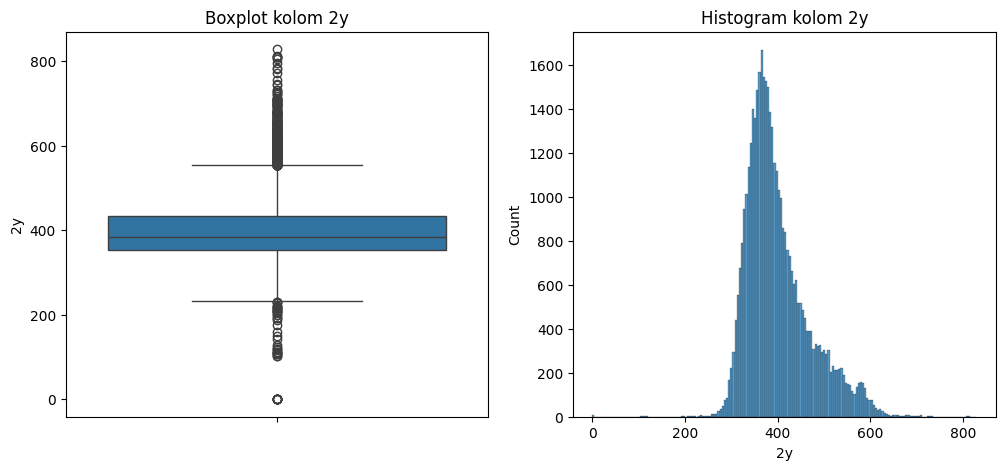

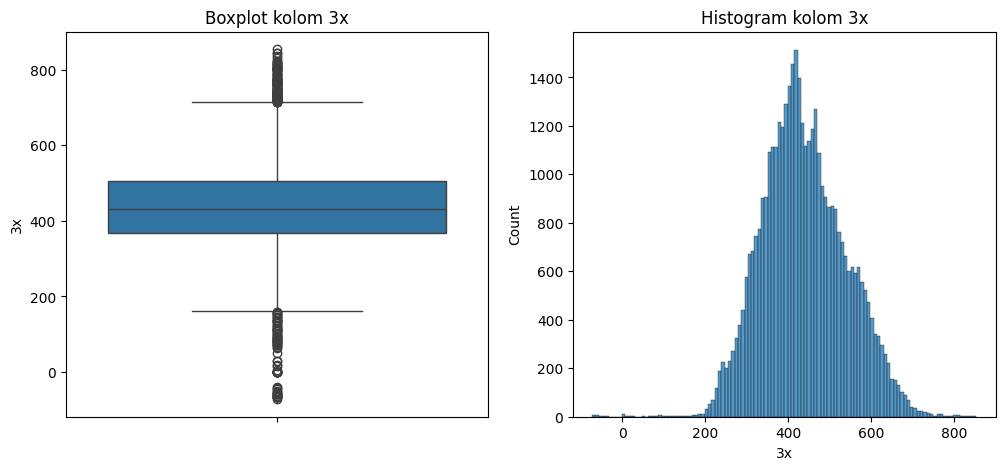

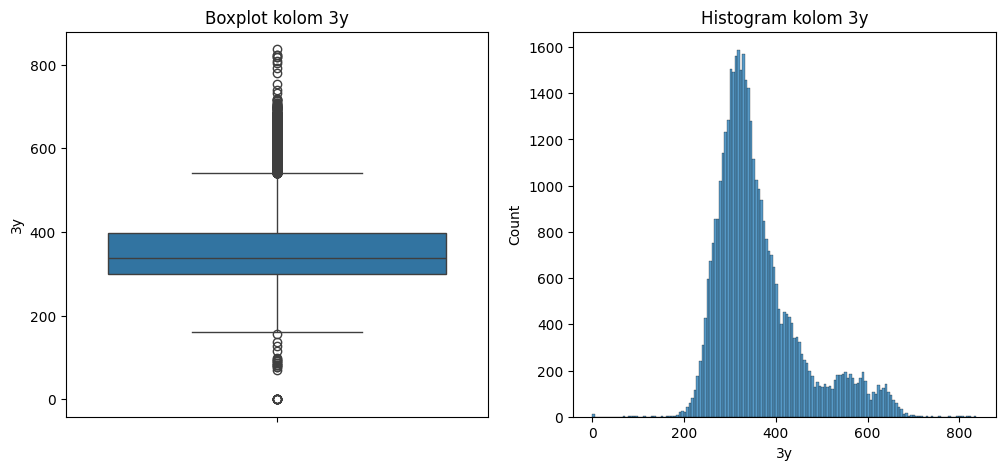

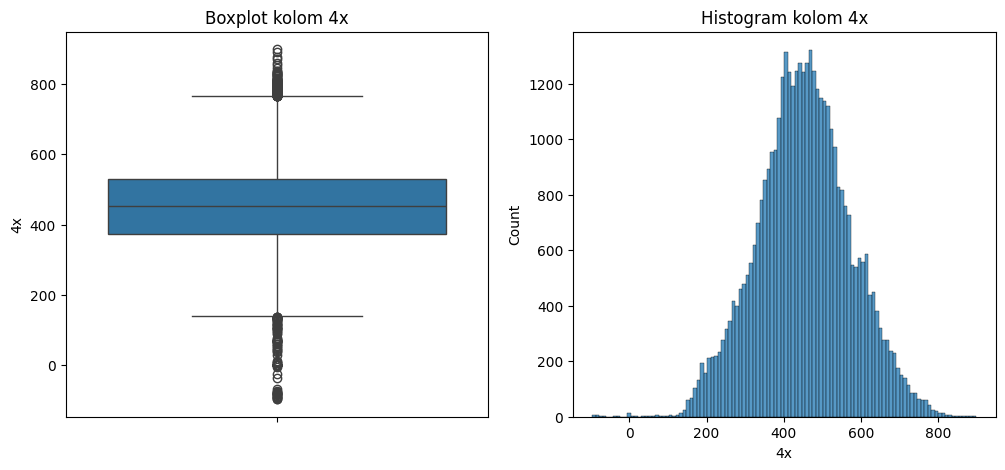

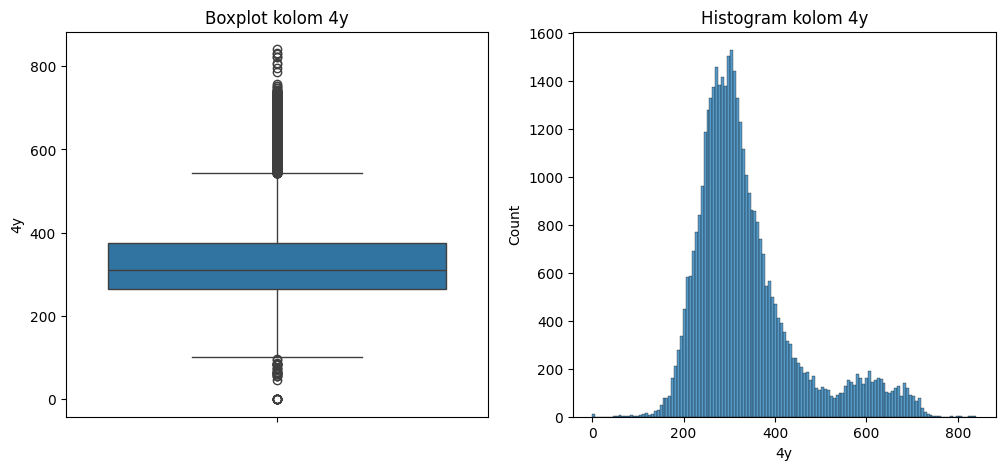

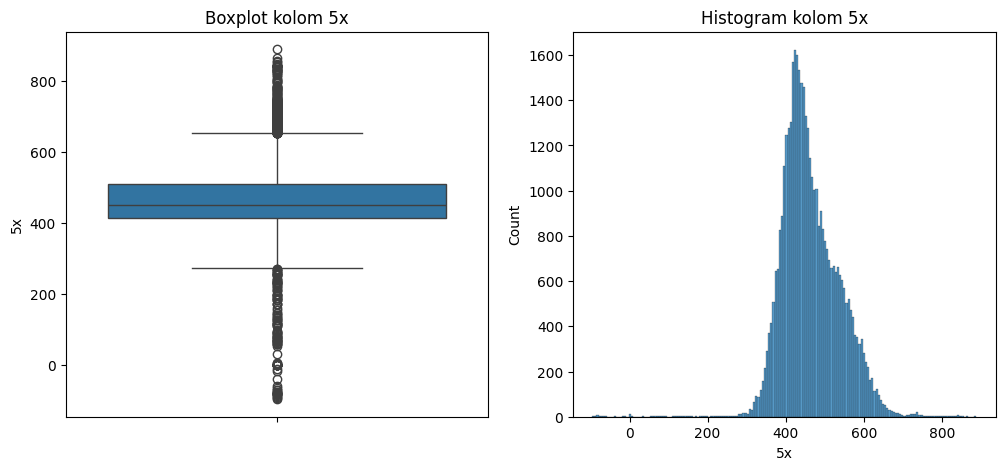

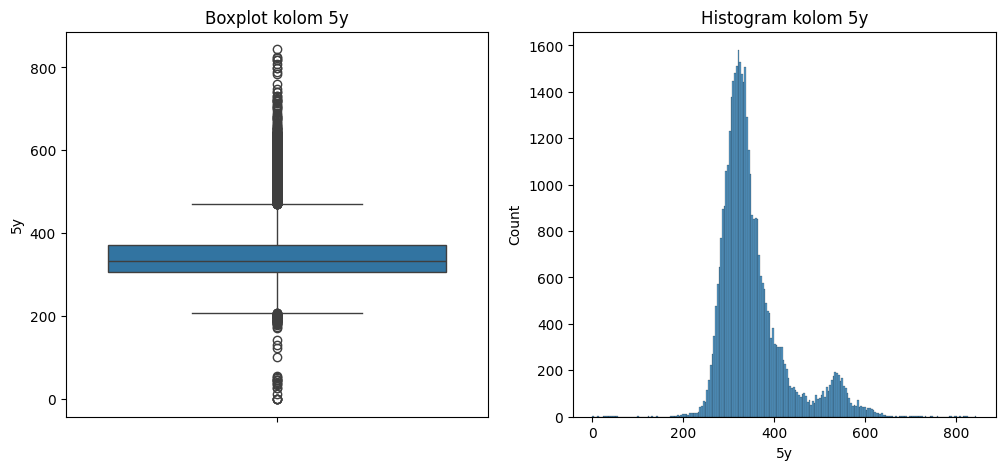

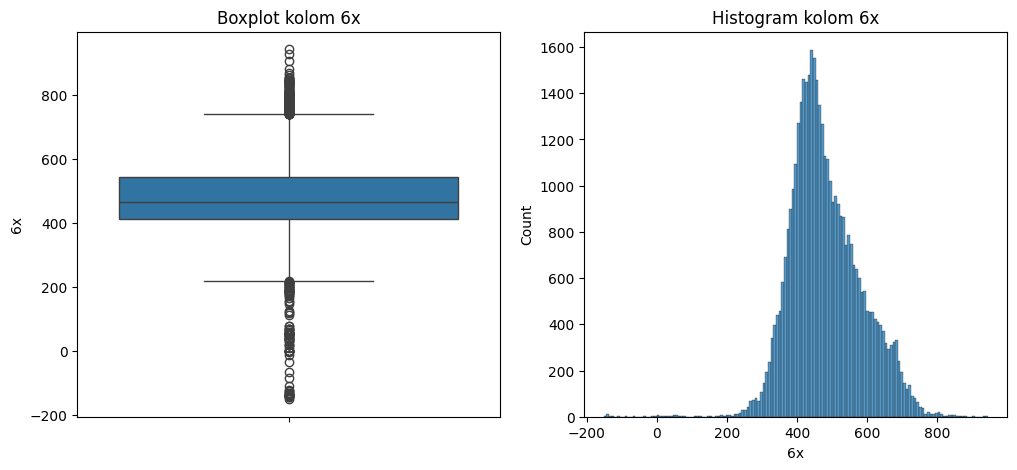

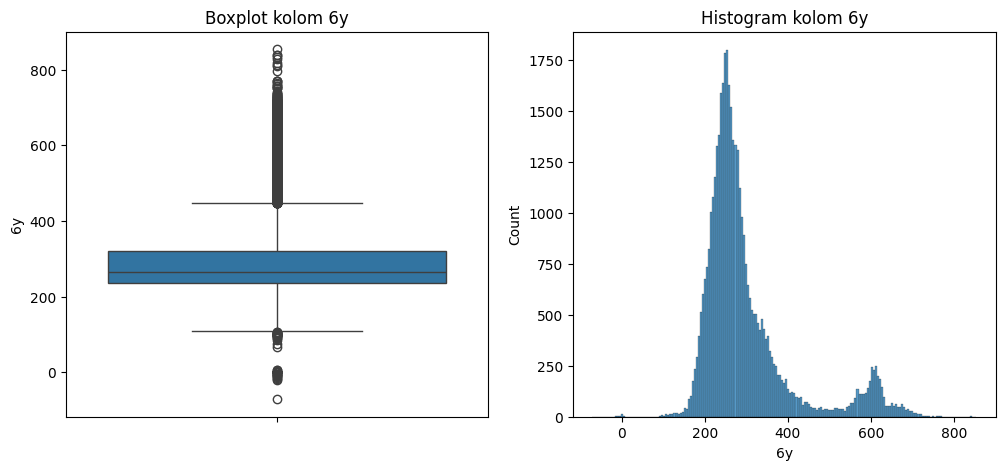

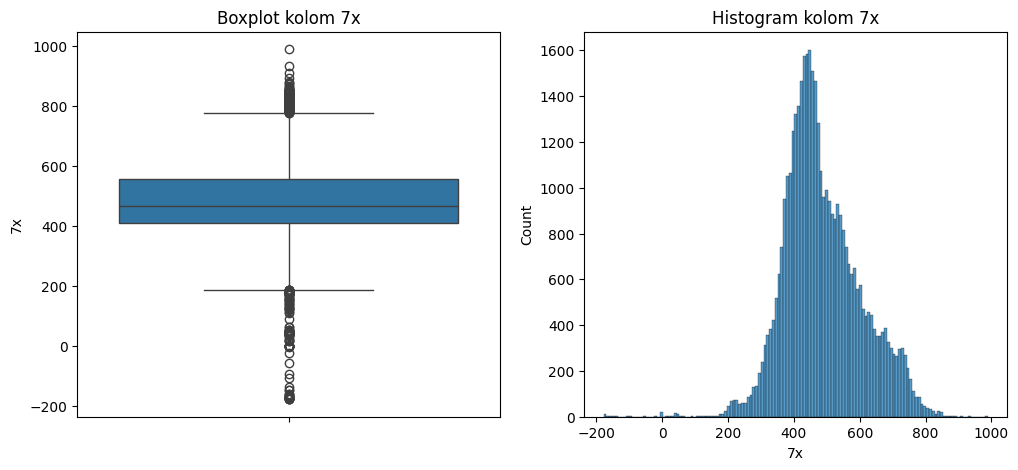

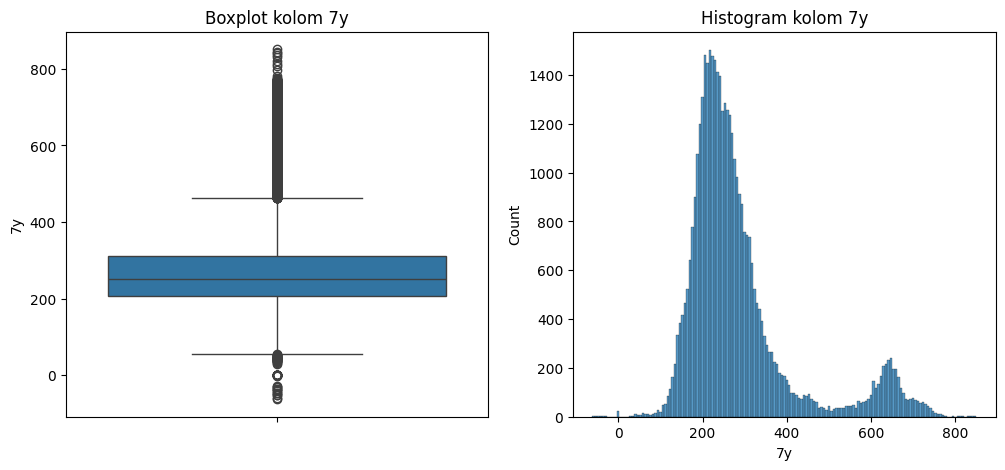

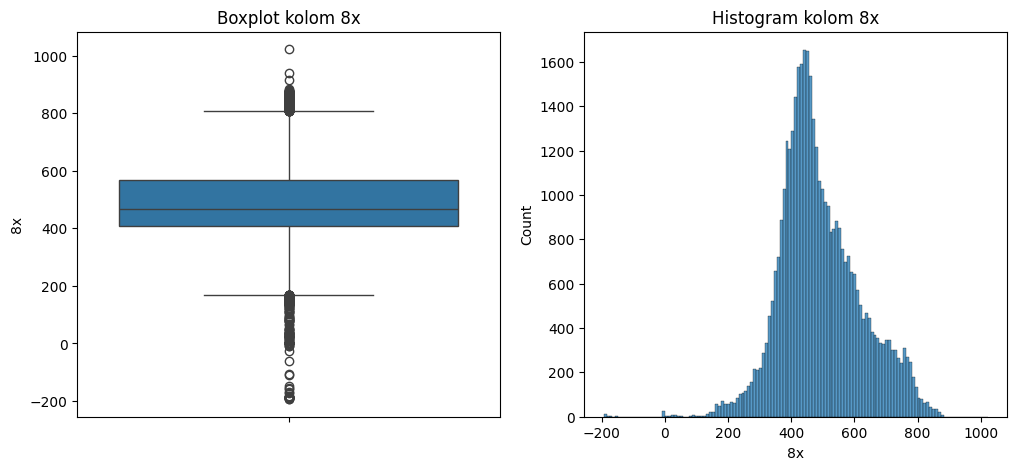

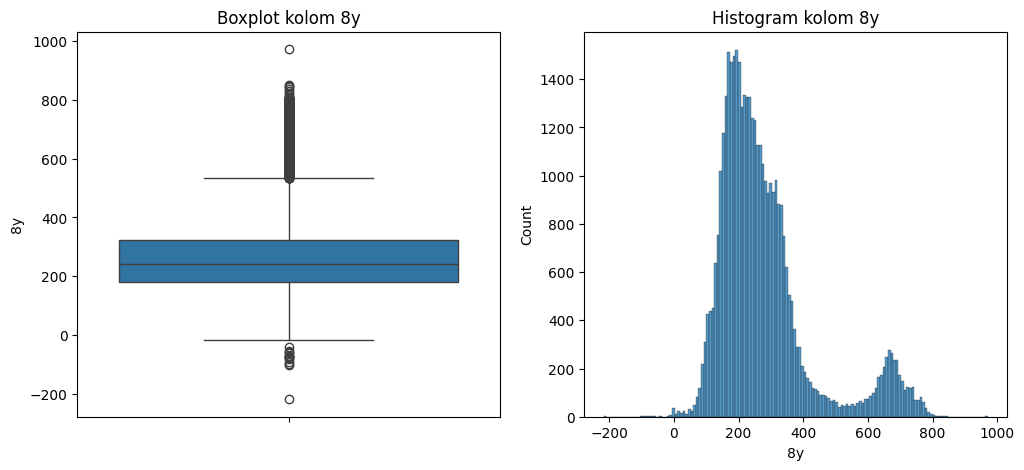

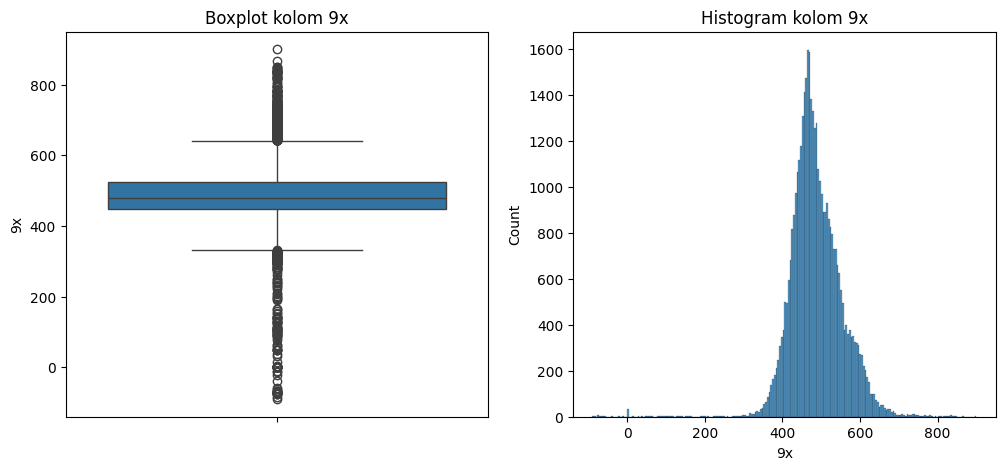

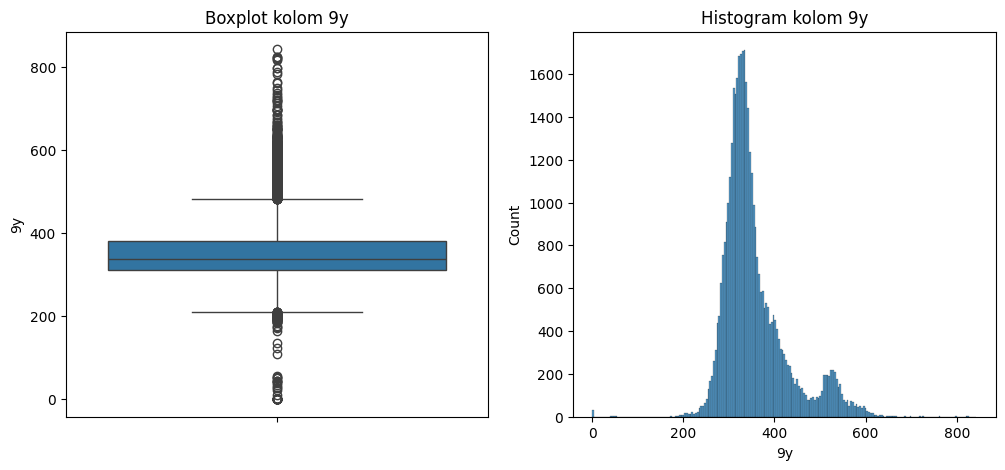

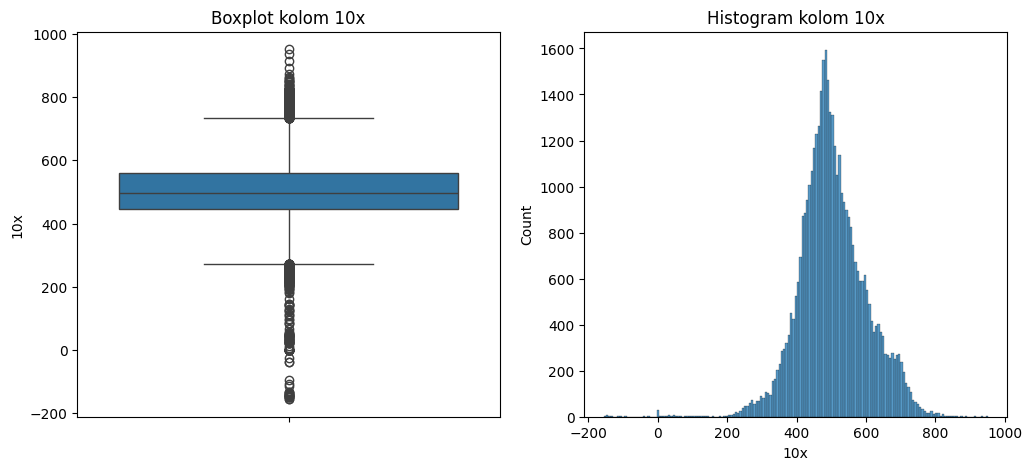

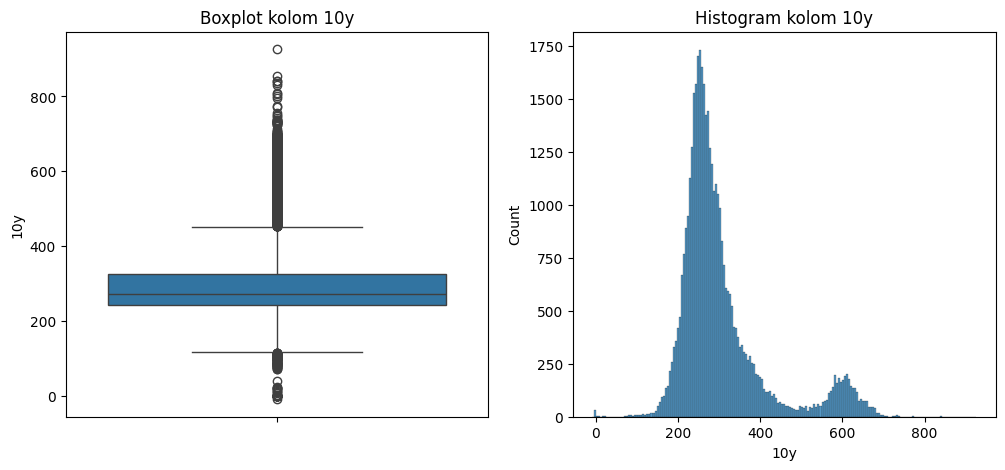

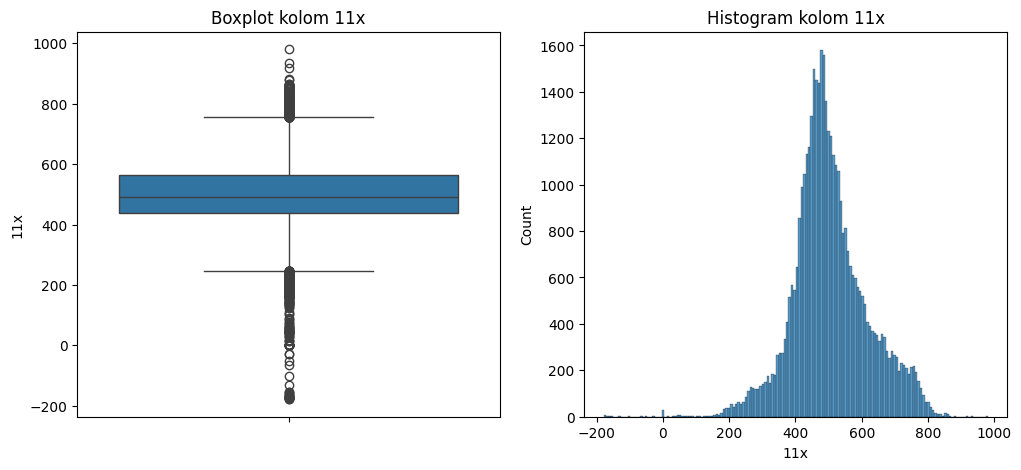

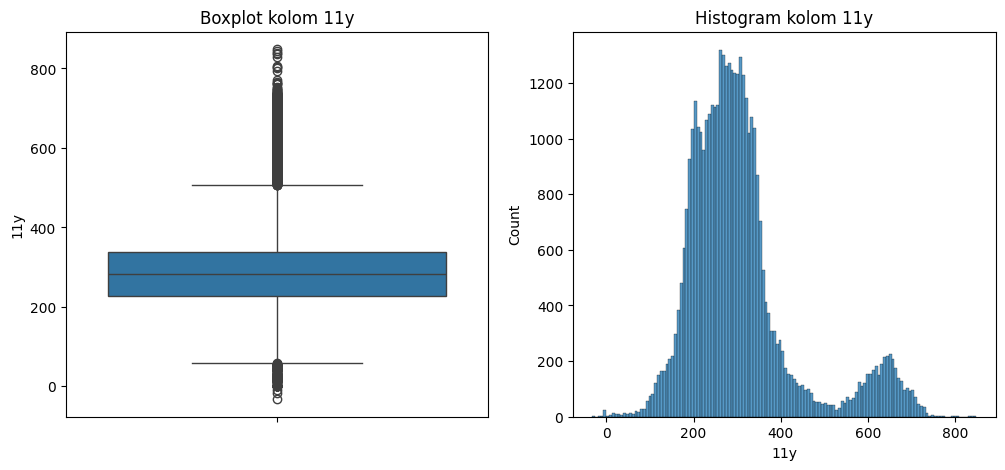

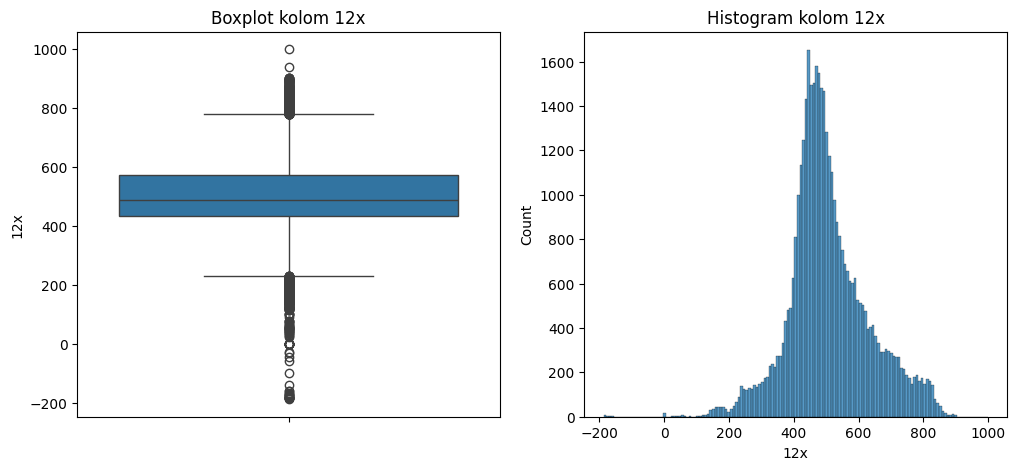

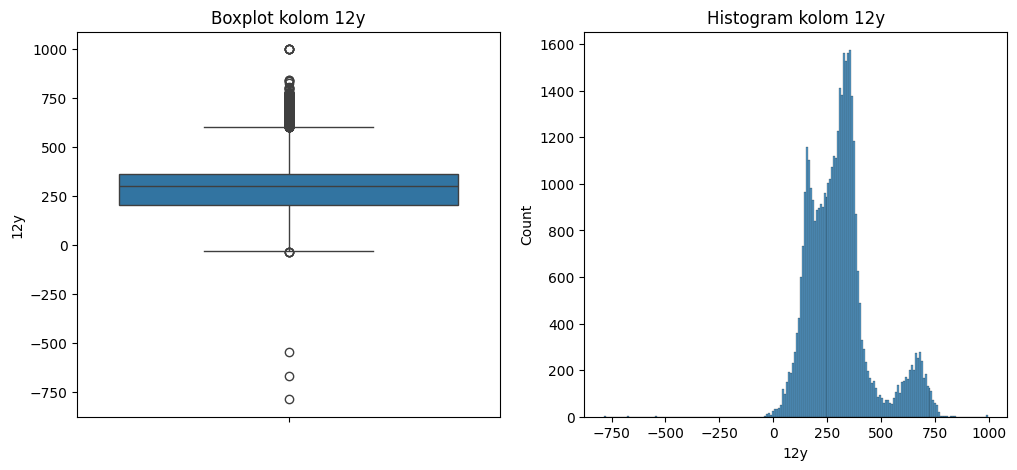

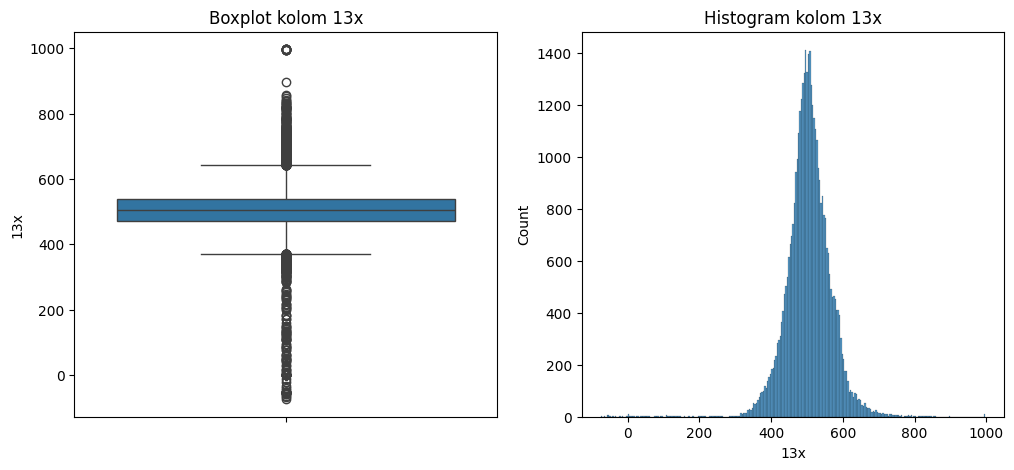

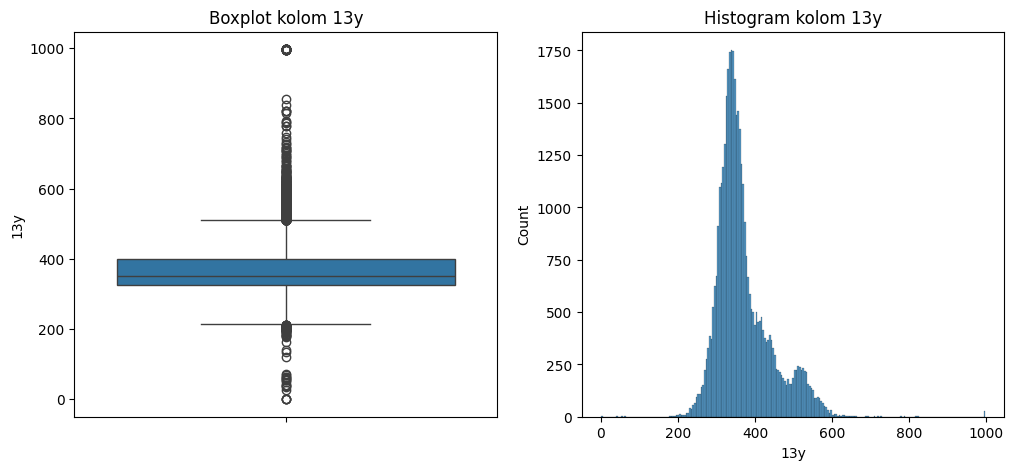

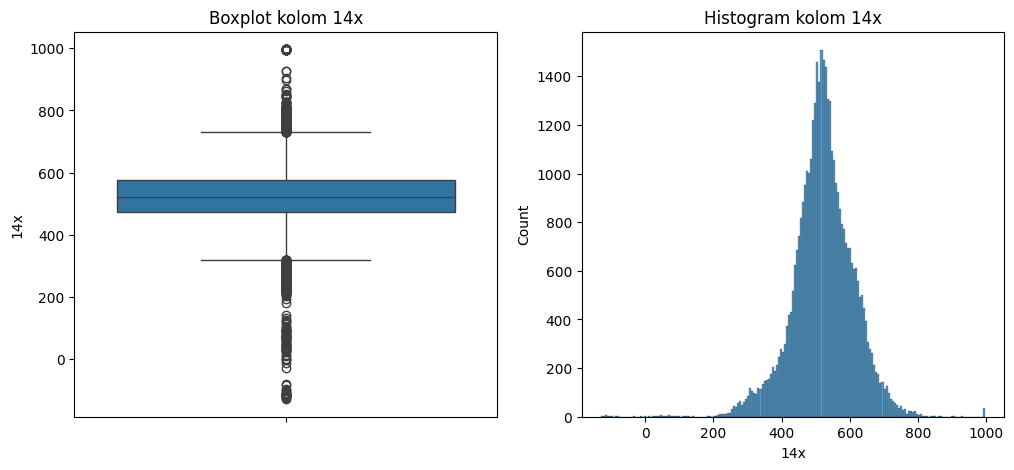

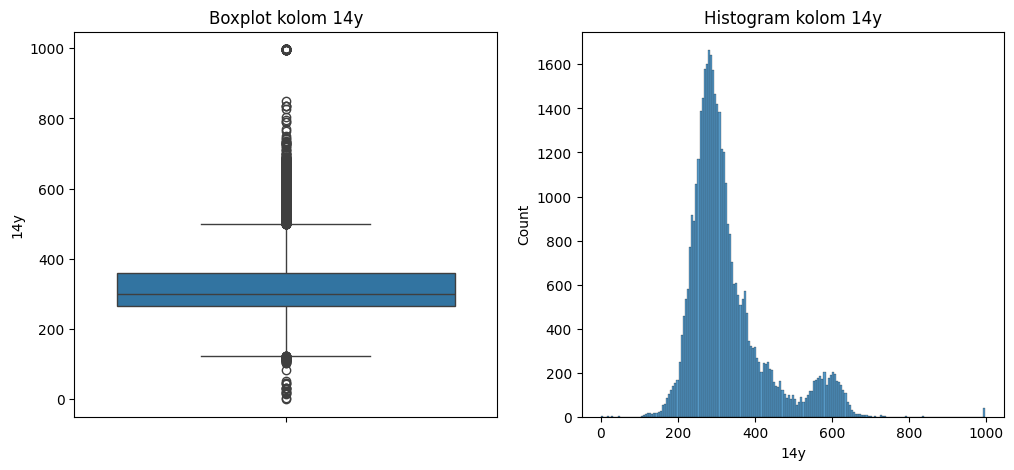

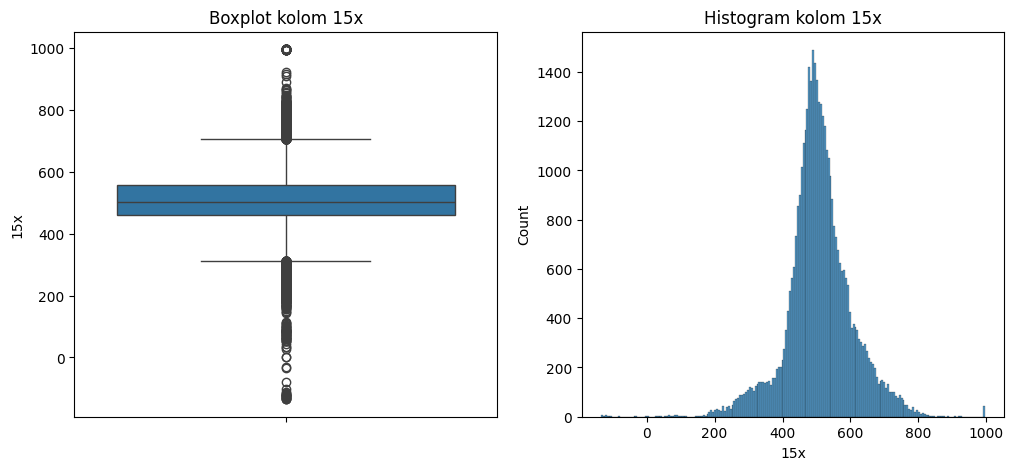

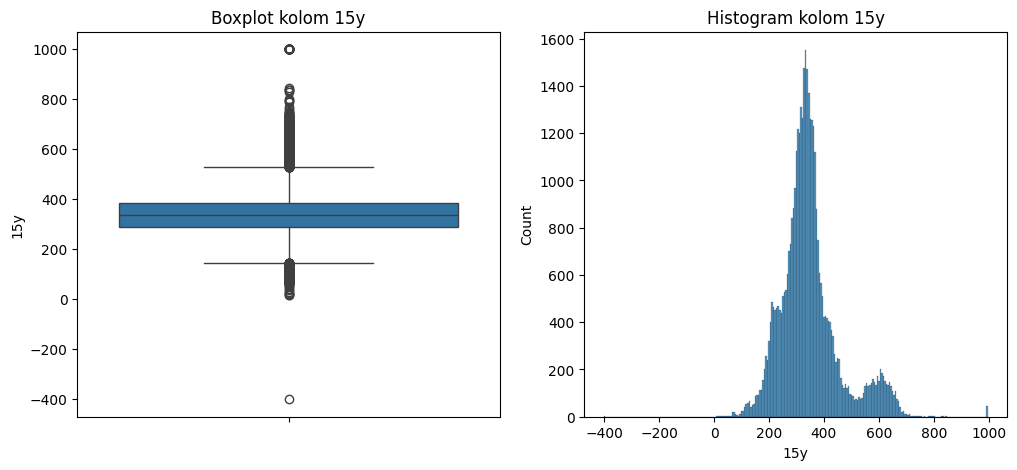

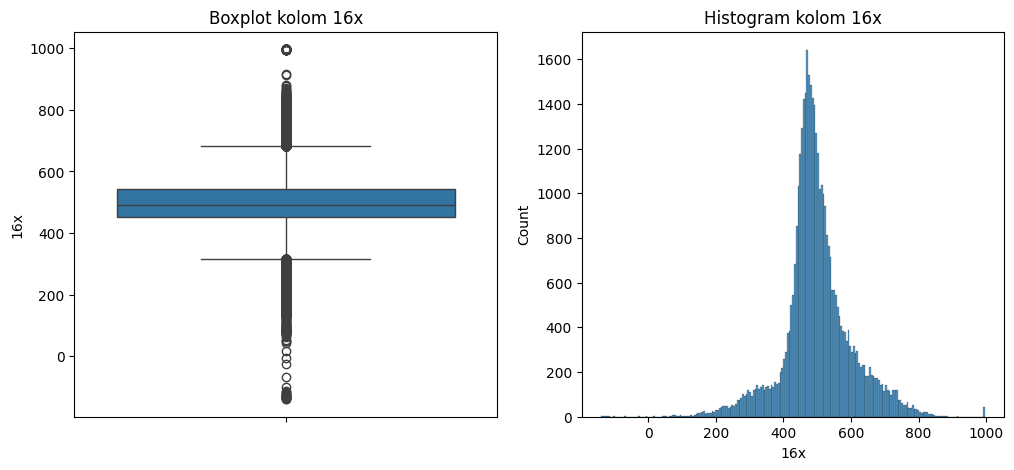

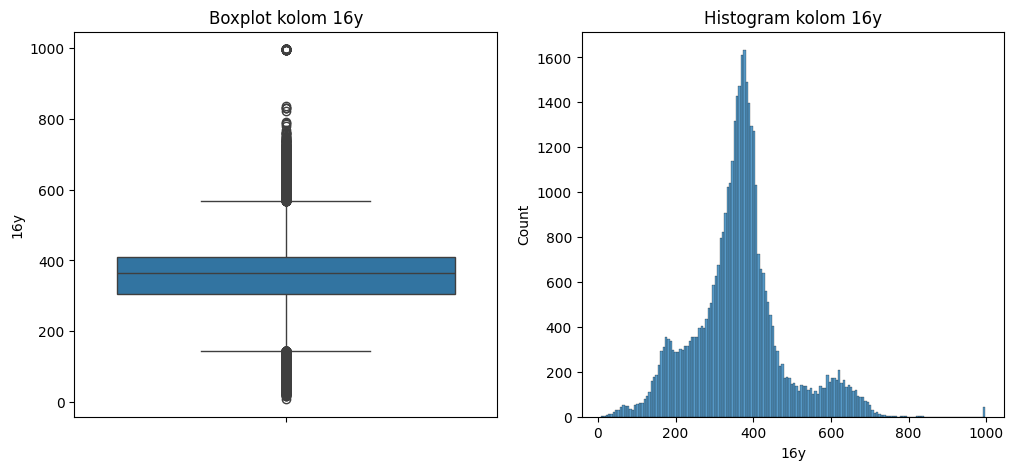

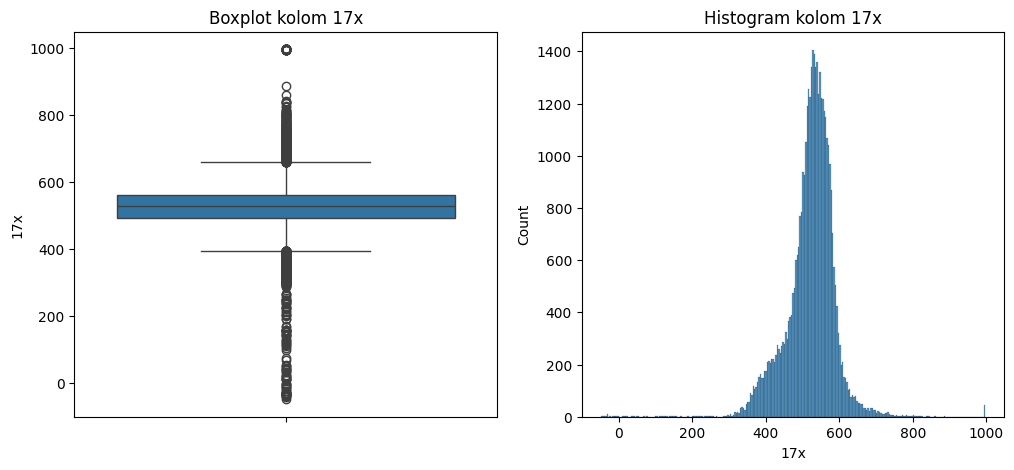

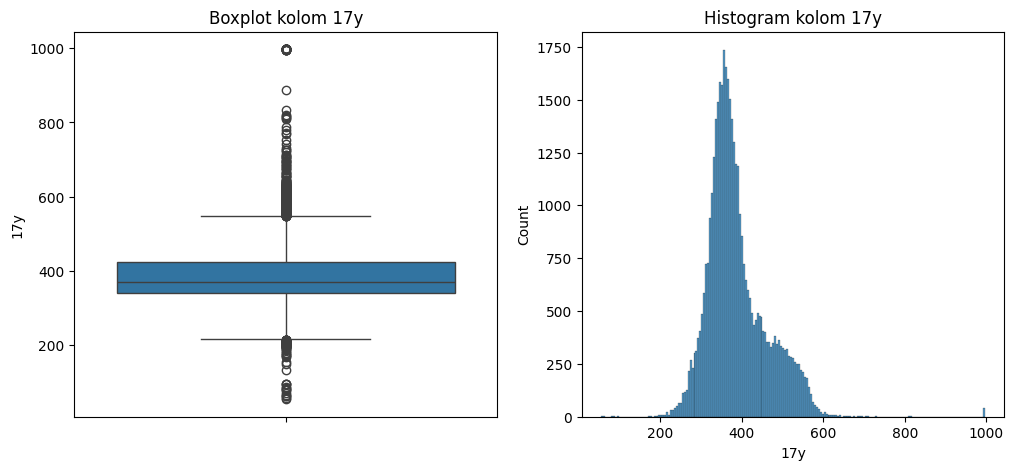

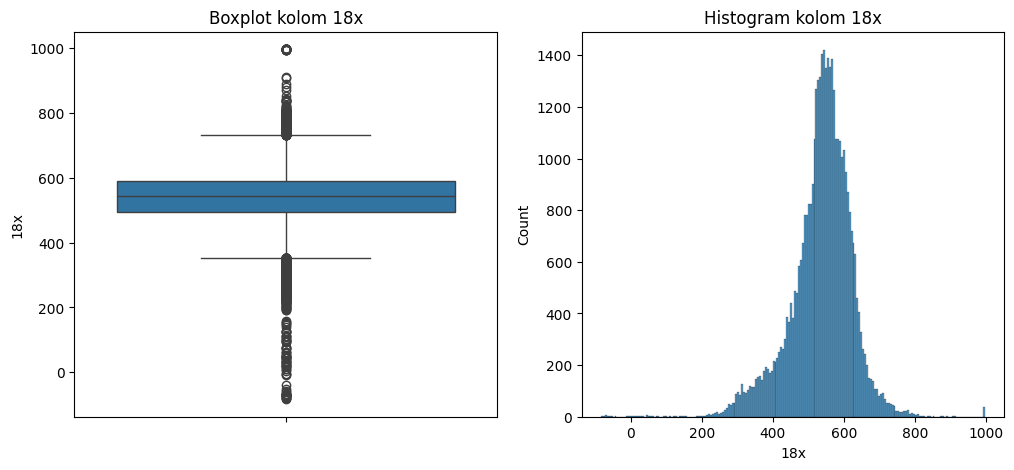

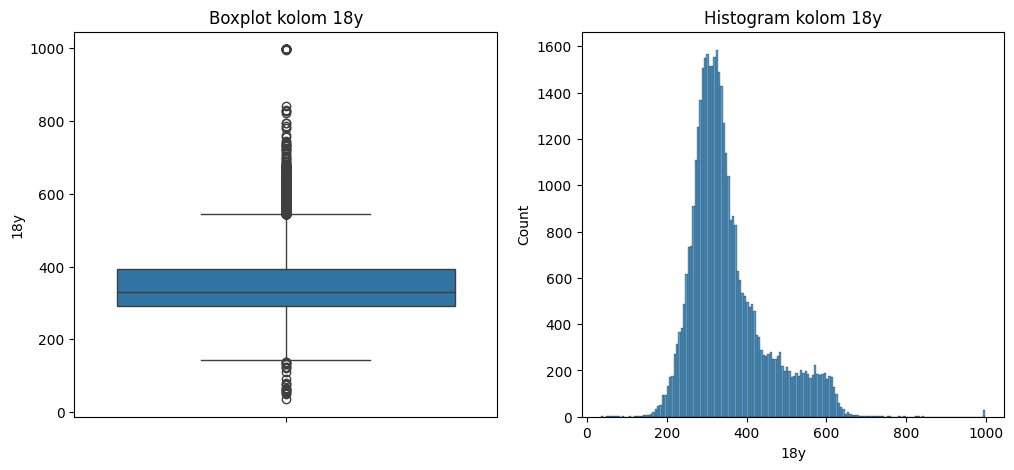

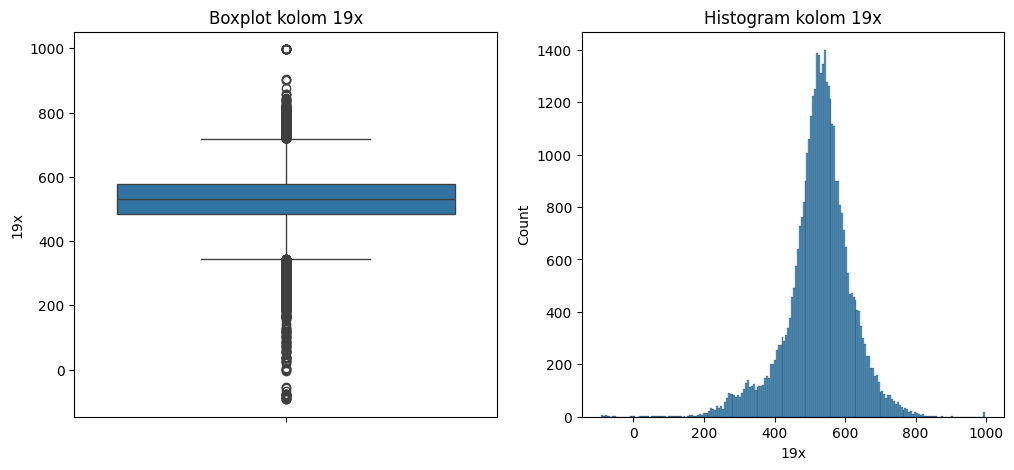

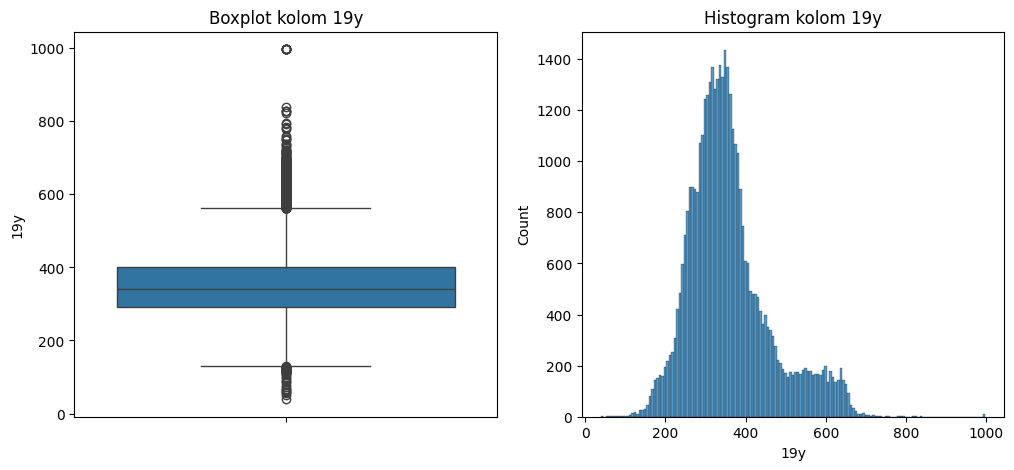

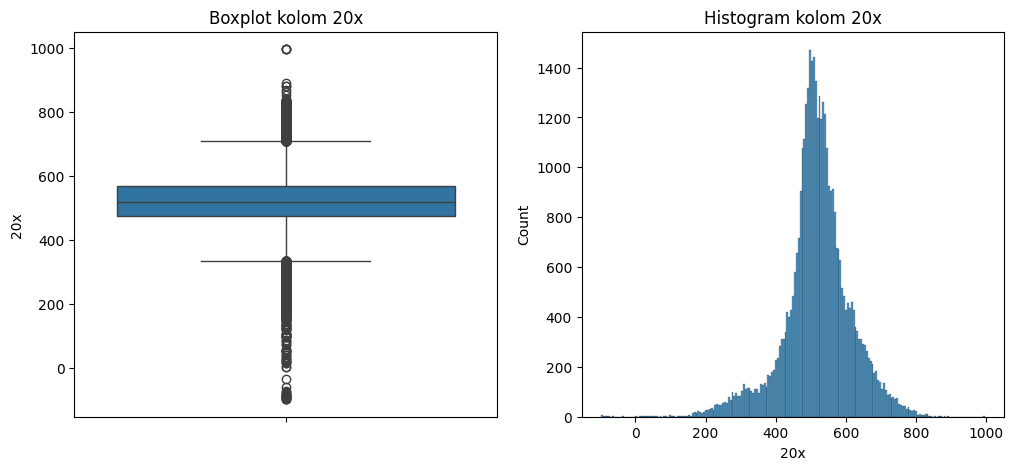

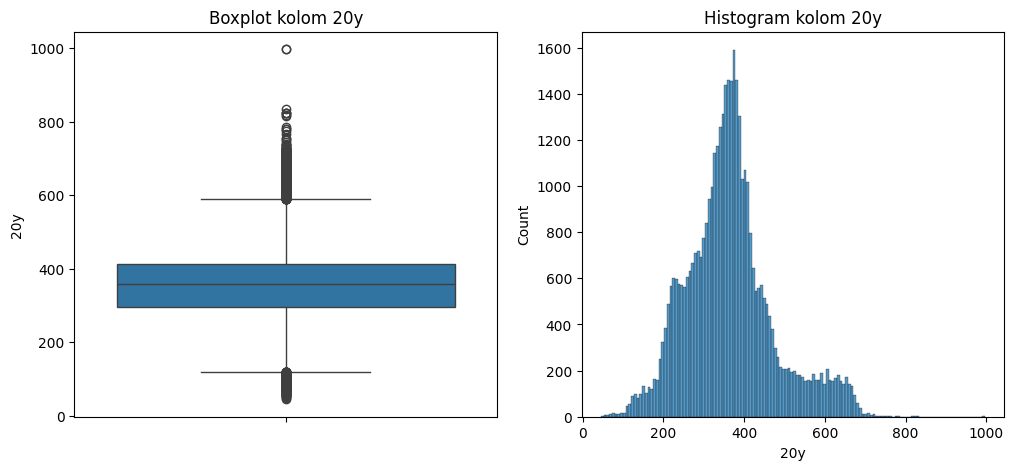

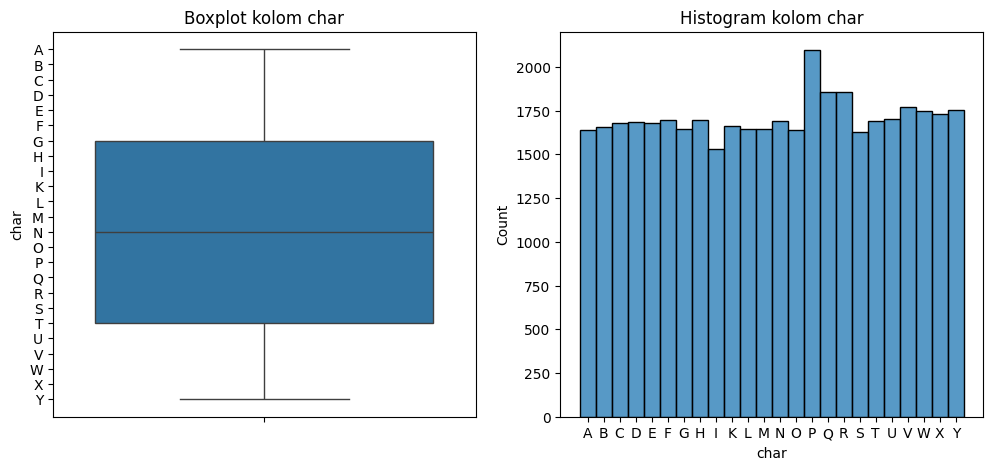

In [14]:
for i in df.columns:
    fig,axes = plt.subplots(1,2,figsize=(12,5))
    
    sns.boxplot(df[i],ax=axes[0])
    axes[0].set_title(f'Boxplot kolom {i}')
    
    sns.histplot(df[i],ax=axes[1])
    axes[1].set_title(f'Histogram kolom {i}')
    plt.show()

**Insight Histogram**: Banyak kolom yang memiliki distribusi yang seimbang, namun beberapa kolom memiliki 'bukit' kecil disebelah 'bukit' utama, namun yang paling menarik adalah **huruf J dan Z yang menghilang dari dataset, dan juga kehilangannya beberapa data pada kolom char**

**Insight Boxplot**: **Tampak outlier namun akan susah jika dilakukan metode seperti IQR dengan range whisker normal**, harus melakukan outlier filtering secara detail, serta beberapa huruf **memiliki jumlah yang lebih sedikit dibanding dengan huruf lain**

## **A.7 Outlier**

**Pengecekan Outlier berdasarkan IQR**

In [15]:
jumlah_iqr = {}
jumlah_iqr25 = {}
for col in df.select_dtypes('number'):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lwr = q1 - 2 * iqr 
    upr = q3 + 2 * iqr
    lwr25 = q1 - 2.5 * iqr 
    upr25 = q3 + 2.5 * iqr
    outliers_iqr = df[(df[col] < lwr) | (df[col] > upr)].sort_index()
    outliers_iqr25 = df[(df[col] < lwr25) | (df[col] > upr25)].sort_index()
    jumlah_iqr[col] = len(outliers_iqr)
    jumlah_iqr25[col] = len(outliers_iqr25)

outliers_iqr

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
10,449.794,555.996,325.156,509.232,251.826,413.215,227.998,283.109,214.394,182.695,...,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,A
577,442.420,471.657,356.080,389.944,313.269,296.879,302.449,219.596,317.921,159.176,...,22.858,578.354,264.046,588.383,160.020,585.102,96.651,581.170,51.872,B
665,706.535,759.290,710.562,782.389,720.391,796.826,728.464,803.536,736.836,805.606,...,784.996,748.844,769.371,751.746,780.415,744.973,782.410,738.199,779.359,C
1246,434.907,451.728,378.484,423.667,355.195,368.669,359.549,313.007,363.882,272.897,...,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,A
2280,444.186,496.208,355.303,427.773,314.948,346.876,311.222,278.609,329.854,232.566,...,46.069,563.269,275.983,570.304,190.583,572.458,123.911,569.584,60.910,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21715,456.575,511.164,420.602,570.165,412.922,624.566,406.555,674.293,398.601,716.195,...,663.850,522.687,589.460,519.329,630.553,503.197,646.407,491.724,650.403,Q
21720,461.399,510.126,428.121,571.893,425.307,631.224,424.503,681.352,421.658,722.483,...,690.936,528.581,583.759,532.338,618.754,519.844,642.661,507.913,655.787,Q
21722,454.378,505.351,418.822,568.218,421.517,627.524,426.451,680.425,431.819,724.180,...,698.160,532.082,599.540,539.941,641.543,527.364,668.914,513.573,683.826,Q
24947,460.428,672.062,470.040,684.198,488.674,693.151,505.942,702.202,521.410,711.491,...,727.378,493.807,709.209,507.954,724.762,510.538,726.709,510.033,721.964,T


In [16]:
outliers_iqr25

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
10,449.794,555.996,325.156,509.232,251.826,413.215,227.998,283.109,214.394,182.695,...,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,A
665,706.535,759.290,710.562,782.389,720.391,796.826,728.464,803.536,736.836,805.606,...,784.996,748.844,769.371,751.746,780.415,744.973,782.410,738.199,779.359,C
1246,434.907,451.728,378.484,423.667,355.195,368.669,359.549,313.007,363.882,272.897,...,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,997.123,A
2674,715.339,771.848,719.027,794.441,727.990,805.985,733.098,808.476,737.909,806.957,...,788.246,752.674,779.320,753.498,785.471,747.208,785.204,742.113,781.558,C
4351,490.719,492.064,445.061,554.630,450.748,601.815,458.203,656.396,470.797,696.178,...,735.334,610.437,633.149,609.882,708.650,595.471,735.353,583.982,736.587,O
4687,380.066,782.729,372.989,797.134,368.749,809.704,368.687,818.107,372.402,822.401,...,821.963,378.879,812.711,381.182,822.421,383.070,821.678,384.558,818.063,P
4688,384.519,787.800,375.761,797.962,371.890,809.730,372.053,817.950,375.451,823.091,...,830.249,383.421,819.326,385.191,829.261,386.917,827.838,389.197,823.849,P
5146,531.195,473.321,497.250,511.518,493.118,553.543,495.053,613.301,495.996,657.622,...,660.535,601.822,573.381,621.520,644.640,623.578,691.864,622.684,717.421,Q
5166,614.469,508.458,572.776,539.446,573.697,585.806,586.735,643.063,595.653,696.126,...,688.025,722.771,593.837,763.557,644.928,779.923,687.740,787.093,720.062,Q
5319,476.390,493.889,491.092,551.520,494.268,593.892,486.896,639.605,488.652,685.882,...,597.770,440.887,572.413,420.028,645.779,416.940,687.258,411.108,709.598,Q


In [17]:
jumlah_iqr

{'0x': 2206,
 '0y': 3030,
 '1x': 347,
 '1y': 584,
 '2x': 144,
 '2y': 535,
 '3x': 85,
 '3y': 1705,
 '4x': 53,
 '4y': 2399,
 '5x': 255,
 '5y': 3034,
 '6x': 133,
 '6y': 3768,
 '7x': 97,
 '7y': 3797,
 '8x': 95,
 '8y': 3282,
 '9x': 371,
 '9y': 2454,
 '10x': 215,
 '10y': 3802,
 '11x': 224,
 '11y': 3448,
 '12x': 318,
 '12y': 1254,
 '13x': 545,
 '13y': 979,
 '14x': 413,
 '14y': 3078,
 '15x': 1036,
 '15y': 2778,
 '16x': 2003,
 '16y': 2034,
 '17x': 905,
 '17y': 233,
 '18x': 742,
 '18y': 1137,
 '19x': 1207,
 '19y': 1159,
 '20x': 1482,
 '20y': 748}

In [18]:
jumlah_iqr25

{'0x': 1573,
 '0y': 2078,
 '1x': 243,
 '1y': 338,
 '2x': 68,
 '2y': 142,
 '3x': 32,
 '3y': 630,
 '4x': 20,
 '4y': 1114,
 '5x': 149,
 '5y': 1847,
 '6x': 73,
 '6y': 3449,
 '7x': 56,
 '7y': 3418,
 '8x': 53,
 '8y': 1755,
 '9x': 257,
 '9y': 946,
 '10x': 118,
 '10y': 3415,
 '11x': 92,
 '11y': 2296,
 '12x': 72,
 '12y': 69,
 '13x': 291,
 '13y': 257,
 '14x': 142,
 '14y': 1595,
 '15x': 357,
 '15y': 1281,
 '16x': 890,
 '16y': 560,
 '17x': 374,
 '17y': 115,
 '18x': 235,
 '18y': 132,
 '19x': 419,
 '19y': 113,
 '20x': 567,
 '20y': 51}

**Kami menggunakan range whisker yang lebih besar dibandingkan dengan boxplot untuk menangkap outlier ekstrim**

## **A.8 Membuat backup dari dataframe untuk menjaga data original**

In [19]:
df_backup = df.copy(deep=True)

## **A.9 Melakukan mapping dan mengecek korelasi kolom fitur dengan kolom target (char)**

**Melakukan Mapping**

In [20]:
df.dropna(subset='char',inplace=True)

In [21]:
char_map = {label: idx for idx,label in enumerate(df['char'].unique())}
df['char'] = df['char'].map(char_map)

**Melakukan visualisasi Heatmap dengan metode korelasi kendall tau**

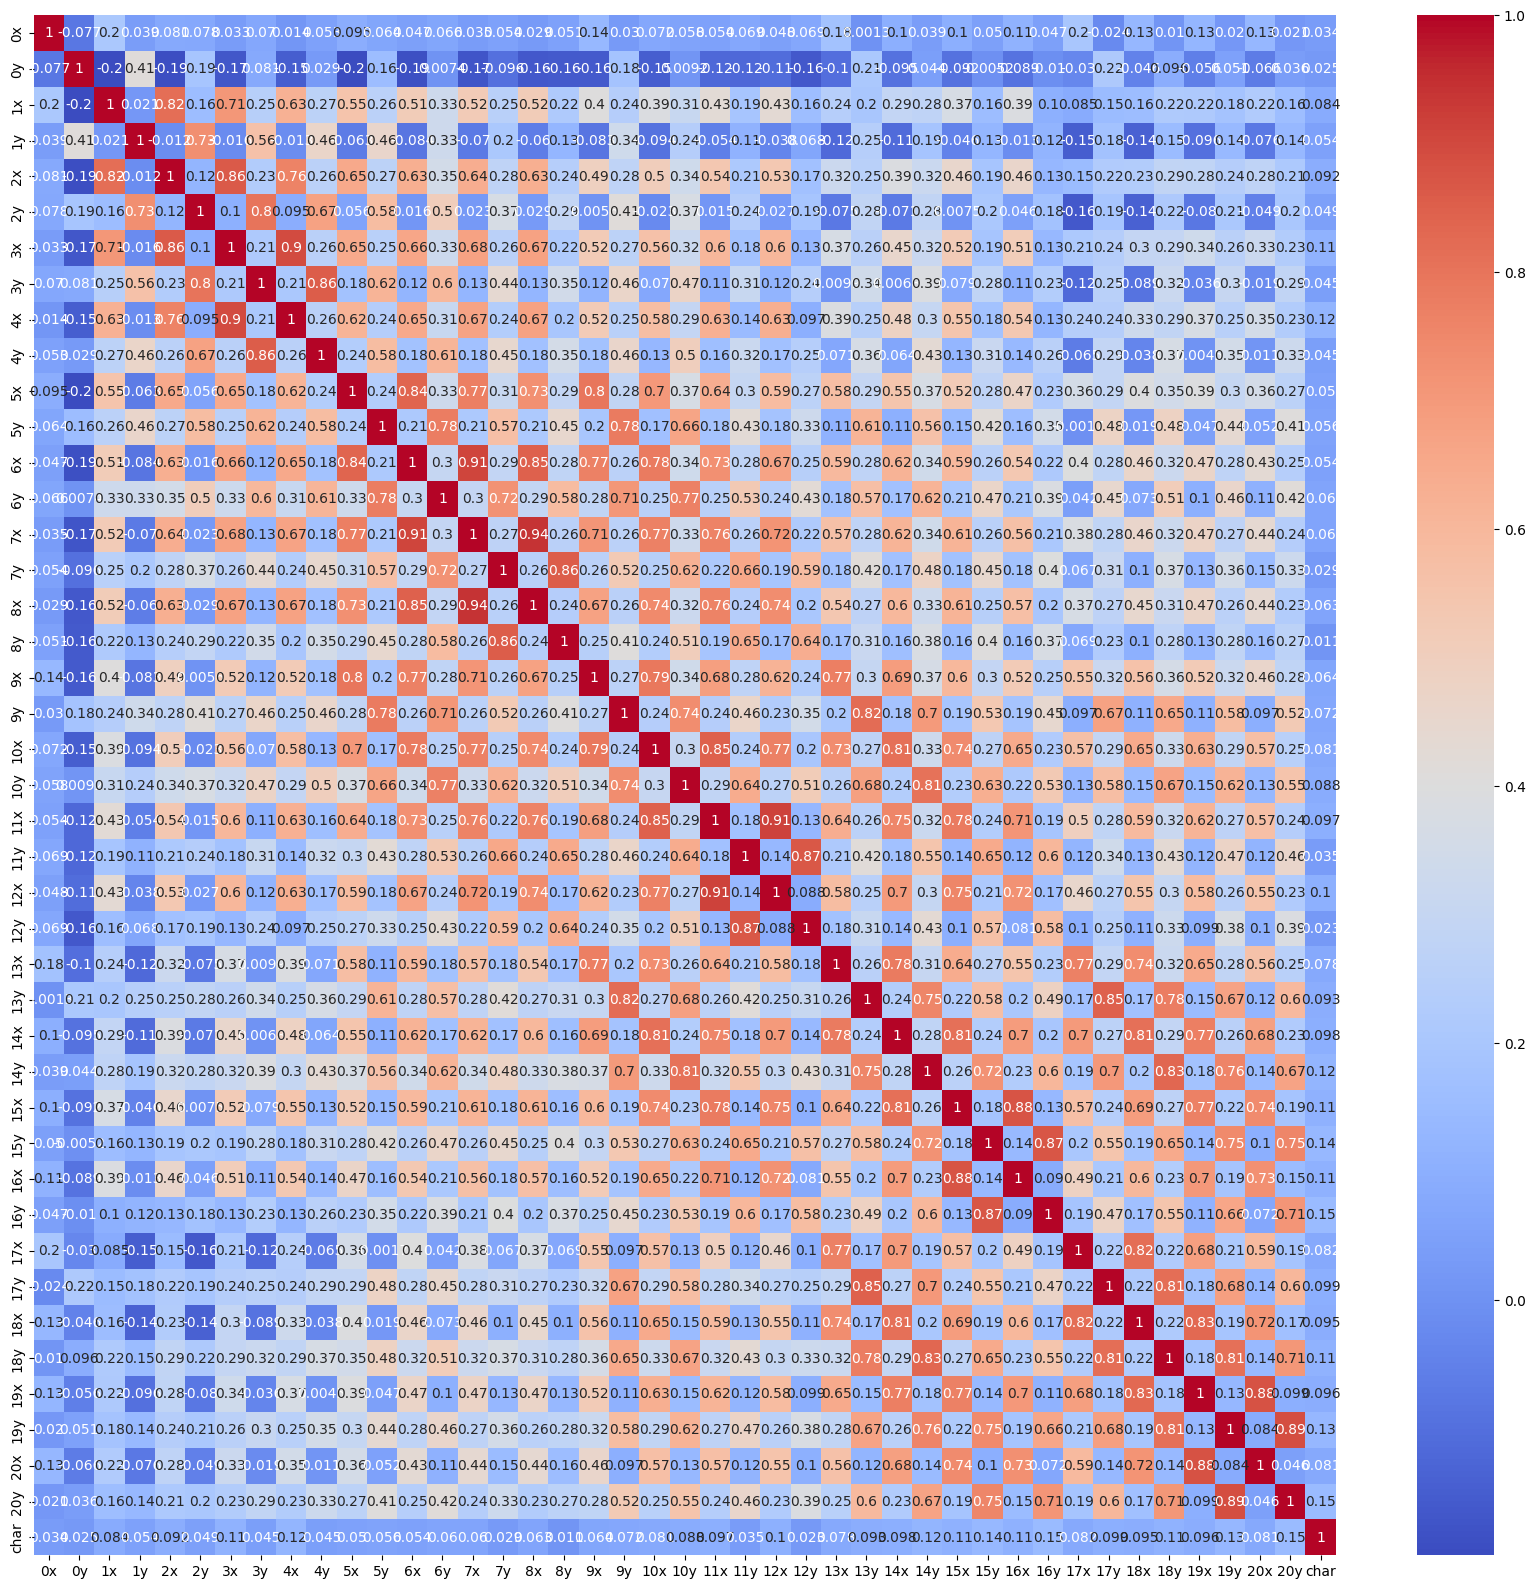

In [22]:
plt.figure(figsize=(21,20))
sns.heatmap(df.corr('kendall'), annot=True,cmap='coolwarm')
plt.show()

**Membuat tingkatan korelasi fitur dengan kolom target dan mengecek fitur yang paling tinggi korelasinya**

In [23]:
df.isna().sum()

0x       0
0y       0
1x       0
1y       0
2x       0
2y       0
3x       0
3y       0
4x       0
4y       0
5x       0
5y       0
6x       0
6y       0
7x       0
7y       0
8x       0
8y       0
9x       0
9y       0
10x      0
10y      0
11x      0
11y      0
12x      0
12y      0
13x      1
13y      0
14x      3
14y      3
15x      4
15y     10
16x      7
16y      3
17x      7
17y      2
18x      1
18y      1
19x      0
19y      0
20x      0
20y      0
char     0
dtype: int64

In [24]:
corr_rank = df.drop(columns='char').apply(lambda x: df['char'].corr(x,method='kendall')).abs().sort_values(ascending=False)
corr_rank.head(29)

16y    0.148004
20y    0.146194
15y    0.136622
19y    0.129790
14y    0.124101
4x     0.123636
18y    0.113460
3x     0.111597
15x    0.110202
16x    0.107759
12x    0.103791
17y    0.098705
14x    0.098251
11x    0.097027
19x    0.095585
18x    0.095237
13y    0.092649
2x     0.092258
10y    0.087732
1x     0.084297
17x    0.081778
10x    0.081498
20x    0.081257
13x    0.078342
9y     0.072112
9x     0.064325
8x     0.062849
7x     0.060284
6y     0.060219
dtype: float64

**`Terlihat Korelasi dari kolom hanya mencapai 14% saja, dan ini mengambil top 29 data dengan korelasi tertinggi. Perlu dilakukan feature engineering dari kolom di dataframe untuk di eksplor lebih lanjut (Mengeksplor Hidden Pattern)`**

In [25]:
for i in range(1,21):
    df[f'{i}xy+'] = df[f'{i}x'] + (df[f'{i}y'] + 1e-8)
    df[f'{i}xy-'] = df[f'{i}x'] - (df[f'{i}y'] + 1e-8)
    df[f'{i}xy*'] = df[f'{i}x'] * (df[f'{i}y'] + 1e-8)
    df[f'{i}xy/'] = df[f'{i}x'] / (df[f'{i}y'] + 1e-8)

**`Diatas kami telah membuat kolom ixy dan membuuat fitur aggregasi sumbu x dan y menggunakan penjumlahan, pengurangan, perkalian, dan pembagian dari angka yang sama dengan sumbu berbeda tersebut`**

In [26]:
corr_rank_new = df.drop(columns='char').apply(lambda x: df['char'].corr(x,method='kendall')).abs().sort_values(ascending=False)
corr_rank_new.head(29)

16xy+    0.172159
16xy*    0.171036
15xy*    0.169475
20xy*    0.168360
15xy+    0.165470
20xy+    0.164124
19xy*    0.156379
19xy+    0.151688
14xy*    0.151301
16y      0.148004
20y      0.146194
14xy+    0.144406
18xy*    0.139545
15y      0.136622
18xy+    0.136194
19y      0.129790
4xy+     0.127707
10xy*    0.126838
4xy*     0.126401
10xy+    0.124212
14y      0.124101
4x       0.123636
3xy*     0.121818
3xy+     0.118748
17xy+    0.117071
17xy*    0.116916
18y      0.113460
3x       0.111597
11xy+    0.110598
dtype: float64

In [27]:
df.shape

(41019, 123)

**`Mengecek rasio split data`**

In [28]:
print(len(df))
print(len(train))
print(len(test))

41019
32849
8213


**`Rasio split data kemungkinan adalah 80:20`**

## **Kesimpulan EDA**:

1. **Tidak ditemukan Huruf J dan Z di dataset ini, Alasan mengapa kedua huruf tersebut tidak ada dikarenakan mereka berdua merupakan huruf yang menggunakan gerakan, bukan sekedar simbol. Maka penggali data harus mengambil data untuk huruf tersebut.**
2. Korelasi antara kolom target (char) dengan kolom fitur sangatlah kecil, ini sangat diduga karena bentuk **korelasi mereka tidak linear**, namun memiliki **hidden pattern yang dapat diungkap dengan membuat kolom perhitungan matematika** antar sumbu berbeda dengan angka yang sama
3. **Terdapat banyak outlier ketika dilihat melalui boxplot**, namun perlu dicatat bahwa kebanyakan **outlier tersebut adalah data asli yang terdeteksi outlier karena diluar standar whisker boxplot** (1.5 * IQR), maka akan dilakukan tahap normalisasi untuk menjaga data yang utuh.
4. **Untuk mengecek outlier yang merupakan outlier asli, kami memutuskan untuk menggunakan whisker 2 & 2.5 dikalikan IQR** agar kami tidak menghitung data asli yang diluar whisker 1.5 boxplot
5. **Kami mengamati bahwa ada data dengan koordinat negatif, kami memutuskan untuk tetap menggunakan data ini untuk prediksi dikarenakan diperlukan, namun kami akan melakukan normalisasi pada data ini.**

## **Langkah preprocessing berdasarkan EDA**:

1. **Mungkin Drop / Mengisi Outlier Extreme saja, Outlier yang mendekati whisker akan di normalisasi**
2. **Untuk Duplikat dapat di drop, karena meningkatkan range dari huruf P**
3. **Untuk NaN kemungkinan akan di drop atau di Isi**
4. **Meninggalkan Huruf J dan Z dikarenakan tidak ditemukan data huruf tersebut, ini disebabkan oleh bentuk dari huruf J dan Z yang berbentuk gerakan bukan gambar**

## **Kesimpulan Bisnis**:

1. **Mesin akan dapat memprediksi bahasa isyarat untuk semua huruf kecuali huruf J dan Z, yang harus dipelajari sendiri karena mereka berbentuk gerakan, yang tidak dapat di ambil oleh sebuah gambar. Maka dari itu, disarankan untuk pelayan untuk mempelajari bahasa isyarat SIBI, dan yang penting adalah memahami bahasa isyarat J dan Z**

---

# **B. Pre Processing**

## **B.1 Menangani Data Outlier**

In [29]:
for col in df.select_dtypes('number'):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lwr = q1 - 2.5 * iqr
    upr = q3 + 2.5 * iqr
    median_val = df[col].median()
    df[col] = df[col].apply(lambda x: median_val if x < lwr or x > upr else x)
    outlier_iqr = df[(df[col] < lwr) | (df[col] > upr)]

outlier_iqr

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,18xy*,18xy/,19xy+,19xy-,19xy*,19xy/,20xy+,20xy-,20xy*,20xy/


**`Kami memutuskan untuk mengganti data outlier ekstrim menggunakan median karena distribusi data yang cukup seimbang dan untuk menjaga data sebanyak mungkin, setelah dilakukan pengecekan Sudah tidak ada outlier lagi`**

## **B.2 Menangani Data Duplikat**

In [30]:
df.drop_duplicates(inplace=True)

**`Kami menghapus duplikat dikarenakan kelas P sendiri sudah memiliki jumlah yang banyak dibanding dengan kelas lain`**

## **B.3 Menangani Data NaN**

In [31]:
df.isna().sum().sum()

np.int64(210)

**`NaN Values menjadi lebih banyak, ini kemungkinan besar berasal dari kolom baru yang kami buat melalui proses matematik`**

In [32]:
df.fillna(df.median())

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,18xy*,18xy/,19xy+,19xy-,19xy*,19xy/,20xy+,20xy-,20xy*,20xy/
1,459.426,468.581,347.614,599.550,273.522,486.969,262.374,354.810,248.102,248.011,...,201640.516761,1.773752,970.518,148.802,229940.788286,1.362174,1003.402,92.926,249545.083037,1.204126
2,444.194,468.581,326.598,616.910,253.226,497.914,243.082,361.876,239.491,259.676,...,196435.146566,1.639990,950.500,116.812,222451.301669,1.280230,975.094,73.472,236352.543518,1.162977
3,443.780,468.581,324.970,607.825,252.818,487.201,244.345,356.561,243.655,256.638,...,196704.580336,1.711388,952.482,129.892,222587.507170,1.315812,973.839,82.285,235397.894179,1.184588
4,452.860,468.581,340.436,595.407,272.323,487.497,254.365,357.569,231.482,241.993,...,196282.343764,1.722651,961.603,141.147,226189.463506,1.344070,996.510,96.638,245923.319269,1.214782
5,457.552,468.581,335.113,436.147,264.734,510.101,253.082,378.250,236.840,269.307,...,203328.803186,1.659087,969.109,127.335,230739.512919,1.302540,995.168,83.692,245838.749345,1.183641
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8208,454.776,476.377,403.617,408.764,391.925,343.421,389.176,279.748,367.133,241.514,...,187706.419206,1.778590,895.034,295.222,178482.457974,1.984382,898.216,340.342,172739.826429,2.220139
8209,449.620,471.150,393.538,421.391,377.734,355.225,367.321,289.840,339.901,244.889,...,178491.822396,1.725622,868.246,280.400,168806.739135,1.953991,868.014,328.870,161323.206830,2.219971
8210,449.519,465.264,394.832,419.211,374.325,353.492,359.242,291.124,329.151,246.300,...,171850.707202,1.758502,851.740,290.802,160223.806105,2.036842,845.786,347.518,148646.299374,2.394904
8211,450.871,475.178,392.631,427.684,372.055,363.563,357.538,299.618,330.009,252.363,...,178451.954705,1.687284,862.061,268.661,167742.608706,1.905497,855.227,318.723,157457.217706,2.188148


**`Kami memutuskan untuk mengganti NaN Values dengan median dikarenakakn distribusi data yang seimbang, serta untuk menjaga keutuhan data yang diberikan`**

## **B.4 Melakukan Feature Engineering (Lagi) untuk membuat fitur baru memiliki nilai tanpa NaN yang asli**

**(Sebelumnya hanyalah penggantian dengan median, yang dapat menjadi misleading fillna)**

In [33]:
for i in range(1,21):
    df[f'{i}xy+'] = df[f'{i}x'] + (df[f'{i}y'] + 1e-8)
    df[f'{i}xy-'] = df[f'{i}x'] - (df[f'{i}y'] + 1e-8)
    df[f'{i}xy*'] = df[f'{i}x'] * (df[f'{i}y'] + 1e-8)
    df[f'{i}xy/'] = df[f'{i}x'] / (df[f'{i}y'] + 1e-8)

**Mengisi NaN dari perhitungan baru dengan Median**

In [34]:
df.isna().sum().sum()

np.int64(210)

In [35]:
df.fillna(df.median(),inplace=True)

## **B.5 Melakukan Train Test Splitting dengan data yang sudah dilakukan preprocessing**

**`Membuat Dataframe Alternatif dengan 35 fitur berdasarkan korelasi tertinggi`**

In [36]:
selected_features = corr_rank_new.head(30).index.tolist()
selected_features.append('char')

In [37]:
df_alt = df[selected_features]
df_alt

,16xy+,16xy*,15xy*,20xy*,15xy+,20xy+,19xy*,19xy+,14xy*,16y,...,4x,3xy*,3xy+,17xy+,17xy*,18y,3x,11xy+,15x,char
1,963.572,232001.864576,202472.682557,249545.083037,904.293,1003.402,229940.788286,970.518,145341.480771,471.021,...,248.102,93092.918943,617.184,1013.145,250049.431706,337.165,262.374,811.065,496.461,0
2,952.756,226935.943664,203008.859324,236352.543518,902.624,975.094,222451.301669,950.500,148276.957091,476.613,...,239.491,87965.541834,604.958,978.833,234432.478096,346.090,243.082,812.323,477.267,0
3,951.898,226519.821962,204171.620423,235397.894179,905.509,973.839,222587.507170,952.482,149477.457935,473.187,...,243.655,87123.897547,600.906,991.741,239911.876270,339.026,244.345,819.123,481.303,0
4,947.934,224536.536293,198426.863936,245923.319269,894.268,996.510,226189.463506,961.603,143138.218269,463.566,...,231.482,90953.038688,611.934,1002.414,245412.070899,337.553,254.365,792.547,485.889,0
5,960.408,230565.916945,202452.700154,245838.749345,902.250,995.168,230739.512919,969.109,149035.931320,474.730,...,236.840,95728.266503,631.332,1015.007,252392.564946,350.078,253.082,815.644,483.699,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8208,886.287,194225.289091,182174.409045,172739.826429,865.562,898.216,178482.457974,895.034,167535.741119,396.766,...,367.133,108871.207652,668.924,928.994,208533.142998,324.864,389.176,822.732,504.370,23
8209,872.721,188209.609483,175976.352815,161323.206830,850.801,868.014,168806.739135,868.246,160305.263477,389.447,...,339.901,106464.318644,657.161,908.210,200101.271141,321.615,367.321,809.105,496.035,23
8210,865.996,185165.570153,172513.253255,148646.299374,842.853,845.786,160223.806105,851.740,154625.241145,384.814,...,329.151,104583.968012,650.366,894.739,193285.533803,312.611,359.242,805.572,492.750,23
8211,868.288,186545.188737,175560.991145,157457.217706,848.131,855.227,167742.608706,862.061,158914.355384,390.146,...,330.009,107124.820488,657.156,903.391,198477.606183,325.212,357.538,807.758,489.415,23


**`Membuat data dummy dari data df dengan jumlah tiap kelas yaitu 500`**

In [38]:
df['char'].value_counts().head(5)

char
14    2068
15    1857
16    1856
20    1768
23    1753
Name: count, dtype: int64

In [39]:
dummy_df = df.groupby('char').head(500).reset_index(drop=True)
dummy_df['char'].value_counts().head(5)

char
0    500
1    500
2    500
3    500
4    500
Name: count, dtype: int64

**`Membuat data dummy alternatif dari data df alternatif dengan jumlah tiap kelas yaitu 500`**

In [40]:
df_alt['char'].value_counts().head(5)

char
14    2068
15    1857
16    1856
20    1768
23    1753
Name: count, dtype: int64

In [41]:
dummy_df_alt = df_alt.groupby('char').head(500).reset_index(drop=True)
dummy_df_alt['char'].value_counts().head(5)

char
0    500
1    500
2    500
3    500
4    500
Name: count, dtype: int64

#### **Note :** 
- **Kami melakukan dummy dengan menyamakan jumlah tiap kelas menjadi 500 baris agar mempercepat proses model kami**
- **Kami gunakan data dummy untuk eksperimen model kami saja**

**`Membagi data dummy menjadi fitur dan label`**

In [42]:
x_dummy = dummy_df.drop(columns='char').values
y_dummy = dummy_df['char'].values

**`Membagi data dummy alternatif menjadi fitur dan label`**

In [43]:
x_dummy_alt = dummy_df_alt.drop(columns='char').values
y_dummy_alt = dummy_df_alt['char'].values

In [44]:
def strat_plit(x, y, test_size=0.2, stratify=None, random_state=42):
    stratify = stratify if stratify is not None else y
    np.random.seed(random_state)
    stratify = np.array(stratify)
    test_indices = []
    train_indices = []
    unique_class, y_indices = np.unique(stratify, return_inverse=True)
    for class_index in range(len(unique_class)):
        class_indices = np.where(y_indices == class_index)[0]
        np.random.shuffle(class_indices)
        n_test = int(len(class_indices) * test_size)
        test_indices.extend(class_indices[:n_test])
        train_indices.extend(class_indices[n_test:])

    test_indices = np.array(test_indices)
    train_indices = np.array(train_indices)

    x_train, x_test = x[train_indices], x[test_indices]
    y_train, y_test = y[train_indices], y[test_indices]

    return x_train, x_test, y_train, y_test

**`Split data dummy menjadi train dan testing`**

In [45]:
x_dummy_train, x_dummy_test, y_dummy_train, y_dummy_test = strat_plit(x_dummy, y_dummy, test_size=0.2, stratify=y_dummy)

In [46]:
y_train_counts_dummy = {label: sum(y == label for y in y_dummy_train) for label in set(y_dummy_train)}
y_test_counts_dummy = {label: sum(y == label for y in y_dummy_test) for label in set(y_dummy_test)}

y_train_proporsi_dummy = {label: count / len(y_dummy_train) * 100 for label, count in y_train_counts_dummy.items()}
y_test_proporsi_dummy = {label: count / len(y_dummy_test) * 100 for label, count in y_test_counts_dummy.items()}

In [47]:
print(f'Proporsi Kelas y_train : {y_train_proporsi_dummy}')

Proporsi Kelas y_train : {np.int64(0): np.float64(4.166666666666666), np.int64(1): np.float64(4.166666666666666), np.int64(2): np.float64(4.166666666666666), np.int64(3): np.float64(4.166666666666666), np.int64(4): np.float64(4.166666666666666), np.int64(5): np.float64(4.166666666666666), np.int64(6): np.float64(4.166666666666666), np.int64(7): np.float64(4.166666666666666), np.int64(8): np.float64(4.166666666666666), np.int64(9): np.float64(4.166666666666666), np.int64(10): np.float64(4.166666666666666), np.int64(11): np.float64(4.166666666666666), np.int64(12): np.float64(4.166666666666666), np.int64(13): np.float64(4.166666666666666), np.int64(14): np.float64(4.166666666666666), np.int64(15): np.float64(4.166666666666666), np.int64(16): np.float64(4.166666666666666), np.int64(17): np.float64(4.166666666666666), np.int64(18): np.float64(4.166666666666666), np.int64(19): np.float64(4.166666666666666), np.int64(20): np.float64(4.166666666666666), np.int64(21): np.float64(4.166666666666

In [48]:
print(f'Proporsi Kelas y_train : {y_test_proporsi_dummy}')

Proporsi Kelas y_train : {np.int64(0): np.float64(4.166666666666666), np.int64(1): np.float64(4.166666666666666), np.int64(2): np.float64(4.166666666666666), np.int64(3): np.float64(4.166666666666666), np.int64(4): np.float64(4.166666666666666), np.int64(5): np.float64(4.166666666666666), np.int64(6): np.float64(4.166666666666666), np.int64(7): np.float64(4.166666666666666), np.int64(8): np.float64(4.166666666666666), np.int64(9): np.float64(4.166666666666666), np.int64(10): np.float64(4.166666666666666), np.int64(11): np.float64(4.166666666666666), np.int64(12): np.float64(4.166666666666666), np.int64(13): np.float64(4.166666666666666), np.int64(14): np.float64(4.166666666666666), np.int64(15): np.float64(4.166666666666666), np.int64(16): np.float64(4.166666666666666), np.int64(17): np.float64(4.166666666666666), np.int64(18): np.float64(4.166666666666666), np.int64(19): np.float64(4.166666666666666), np.int64(20): np.float64(4.166666666666666), np.int64(21): np.float64(4.166666666666

**Insight :**
- **Proporsi kelas pada y_train_dummy dan y_test_dummy hampir seimbang**
- **Contoh** :
    - Kelas 0 pada y_train_dummy : 4.16%
    - Kelas 0 pada y_test_dummy : 4.16%

**`Split data dummy alternatif menjadi train dan testing`**

In [49]:
x_dummy_train_alt, x_dummy_test_alt, y_dummy_train_alt, y_dummy_test_alt = strat_plit(x_dummy_alt, y_dummy_alt, test_size=0.2, stratify=y_dummy_alt)

In [50]:
y_train_counts_dummy_alt = {label: sum(y == label for y in y_dummy_train_alt) for label in set(y_dummy_train_alt)}
y_test_counts_dummy_alt = {label: sum(y == label for y in y_dummy_test_alt) for label in set(y_dummy_test_alt)}

y_train_proporsi_dummy_alt = {label: count / len(y_dummy_train_alt) * 100 for label, count in y_train_counts_dummy_alt.items()}
y_test_proporsi_dummy_alt = {label: count / len(y_dummy_test_alt) * 100 for label, count in y_test_counts_dummy_alt.items()}

In [51]:
print(f'Proporsi Kelas y_train : {y_train_proporsi_dummy_alt}')

Proporsi Kelas y_train : {np.int64(0): np.float64(4.166666666666666), np.int64(1): np.float64(4.166666666666666), np.int64(2): np.float64(4.166666666666666), np.int64(3): np.float64(4.166666666666666), np.int64(4): np.float64(4.166666666666666), np.int64(5): np.float64(4.166666666666666), np.int64(6): np.float64(4.166666666666666), np.int64(7): np.float64(4.166666666666666), np.int64(8): np.float64(4.166666666666666), np.int64(9): np.float64(4.166666666666666), np.int64(10): np.float64(4.166666666666666), np.int64(11): np.float64(4.166666666666666), np.int64(12): np.float64(4.166666666666666), np.int64(13): np.float64(4.166666666666666), np.int64(14): np.float64(4.166666666666666), np.int64(15): np.float64(4.166666666666666), np.int64(16): np.float64(4.166666666666666), np.int64(17): np.float64(4.166666666666666), np.int64(18): np.float64(4.166666666666666), np.int64(19): np.float64(4.166666666666666), np.int64(20): np.float64(4.166666666666666), np.int64(21): np.float64(4.166666666666

In [52]:
print(f'Proporsi Kelas y_train : {y_test_proporsi_dummy_alt}')

Proporsi Kelas y_train : {np.int64(0): np.float64(4.166666666666666), np.int64(1): np.float64(4.166666666666666), np.int64(2): np.float64(4.166666666666666), np.int64(3): np.float64(4.166666666666666), np.int64(4): np.float64(4.166666666666666), np.int64(5): np.float64(4.166666666666666), np.int64(6): np.float64(4.166666666666666), np.int64(7): np.float64(4.166666666666666), np.int64(8): np.float64(4.166666666666666), np.int64(9): np.float64(4.166666666666666), np.int64(10): np.float64(4.166666666666666), np.int64(11): np.float64(4.166666666666666), np.int64(12): np.float64(4.166666666666666), np.int64(13): np.float64(4.166666666666666), np.int64(14): np.float64(4.166666666666666), np.int64(15): np.float64(4.166666666666666), np.int64(16): np.float64(4.166666666666666), np.int64(17): np.float64(4.166666666666666), np.int64(18): np.float64(4.166666666666666), np.int64(19): np.float64(4.166666666666666), np.int64(20): np.float64(4.166666666666666), np.int64(21): np.float64(4.166666666666

**Insight :**
- **Proporsi kelas pada y_train_dummy_alt dan y_test_dummy_alt hampir seimbang**
- **Contoh** :
    - Kelas 0 pada y_train_dummy_alt : 4.16%
    - Kelas 0 pada y_test_dummy_alt : 4.16%

## **B.6 Normalisasi**

In [53]:
def normalisasi(train, test):
    min_val = np.min(train, axis=0)
    max_val = np.max(train, axis=0)
    denominator = max_val - min_val
    denominator = denominator.astype('float')
    denominator[denominator == 0] += 1e-10
    train_scaled = (train - min_val) / denominator
    test_scaled = (test - min_val) / denominator
    return train_scaled, test_scaled, min_val, denominator

**`Normalisasi pada train dan test dummy`**

In [54]:
x_dummy_train_scaled, x_dummy_test_scaled, dummy_min, dummy_denom = normalisasi(x_dummy_train, x_dummy_test)

**`Normalisasi pada train dan test dummy alternatif`**

In [55]:
x_dummy_train_alt_scaled, x_dummy_test_alt_scaled, dummy_min_alt, dummy_denom_alt = normalisasi(x_dummy_train_alt, x_dummy_test_alt)

## **B.7 Melakukan Principal Component Analysis**

In [56]:
def pca(x):
    x_centered = x - np.mean(x, axis=0)
    eigval, eigvec = np.linalg.eig(np.cov(x_centered,rowvar=False))
    sorted_indices = np.argsort(eigval)[::-1]
    return eigval[sorted_indices], eigvec[:, sorted_indices]

In [57]:
def transform(x, eigenvectors, n_components):
    return np.dot(x - np.mean(x, axis=0), eigenvectors[:, :n_components])

**`Mereduksi dimensi pada data dummy`**

In [58]:
eigenvalues_dummy, eigenvectors_dummy = pca(x_dummy_train_scaled)
explained_variance_dummy = eigenvalues_dummy / eigenvalues_dummy.sum()
cumulative_variance_dummy = np.cumsum(explained_variance_dummy)

c:\Users\TEKNISI\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\TEKNISI\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


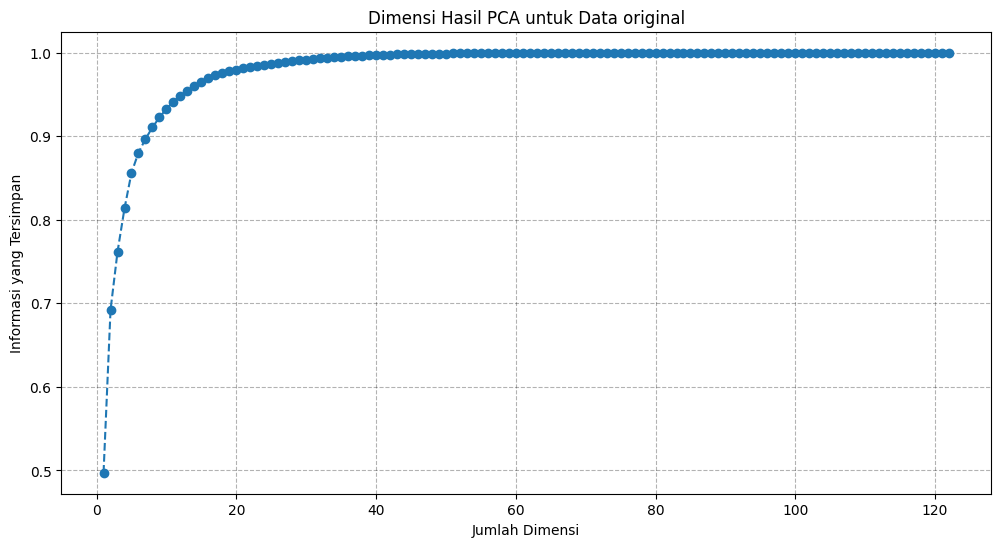

In [59]:
plt.figure(figsize=(12, 6))
plt.plot(range(1, len(explained_variance_dummy) + 1), cumulative_variance_dummy, marker='o', linestyle='--')
plt.title("Dimensi Hasil PCA untuk Data original")
plt.grid(linestyle='--', alpha=0.3, color='black')
plt.xlabel('Jumlah Dimensi')
plt.ylabel('Informasi yang Tersimpan')
plt.show()

In [60]:
x_dummy_train_pca = transform(x_dummy_train_scaled, eigenvectors_dummy, n_components=10)
x_dummy_test_pca = transform(x_dummy_test_scaled, eigenvectors_dummy, n_components=10)

**`Mereduksi dimensi pada data dummy alternatif`**

In [61]:
eigenvalues_dummy_alt, eigenvectors_dummy_alt = pca(x_dummy_train_alt_scaled)
explained_variance_dummy_alt = eigenvalues_dummy_alt / eigenvalues_dummy_alt.sum()
cumulative_variance_dummy_alt = np.cumsum(explained_variance_dummy_alt)

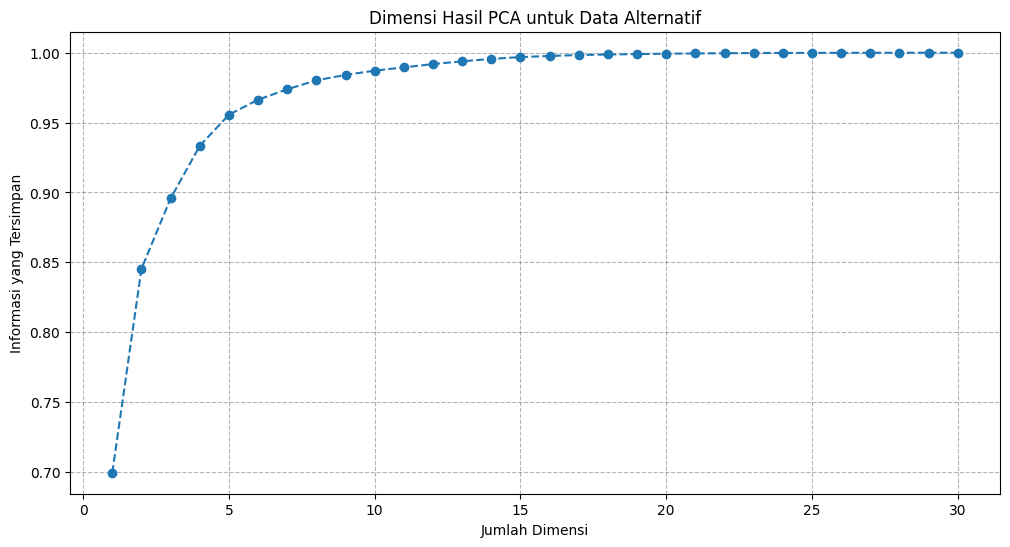

In [62]:
plt.figure(figsize=(12, 6))
plt.plot(range(1, len(explained_variance_dummy_alt) + 1), cumulative_variance_dummy_alt, marker='o', linestyle='--')
plt.title("Dimensi Hasil PCA untuk Data Alternatif")
plt.grid(linestyle='--', alpha=0.3, color='black')
plt.xlabel('Jumlah Dimensi')
plt.ylabel('Informasi yang Tersimpan')
plt.show()

In [63]:
x_train_dummy_alt_pca = transform(x_dummy_train_alt_scaled, eigenvectors_dummy_alt, n_components=7)
x_test_dummy_alt_pca = transform(x_dummy_test_alt_scaled, eigenvectors_dummy_alt, n_components=7)

---

## **Kesimpulan Tahap Preprocessing:**

1. Mengganti Outlier dengan Median
2. Menghapus Data duplikat
3. Mengganti NaN dengan Median
4. Membuat Ulang fitur Matematika dari EDA untuk menghitung dengan data yang sudah di preprocess
5. Melakukan Splitting data dengan rasio 80:20 untuk 3 Macam dataframe, 
6. Melakukan PCA pada dataframe seluruh fitur

- Dataframe dengan seluruh fitur (PCA)
- Dataframe Alternatif dengan 35 fitur dengan korelasi tertinggi
- Dataframe Alternatif dengan jumlah data yang lebih kecil (Undersampling)

---

# **C. Implementasi Model**

**Parameter** :
1. **n_neighbours** : jumlah tetangga yang dipilih
2. **metric** : pengukuran jarak
3. **p** : pangkat untuk metric Manhattan

**Parameter metric** :
1. **Euclidean** : 
    - mengukur jarak lurus antara 2 titik
    - cocok untuk data geomteris
2. **Manhattan** : 
    - mengukur jarak zig-zag antara 2 titk
    - cocok untuk data non geometris
3. **Minkowski** :
    - p = 1 : pengukuran jarak seperti Euclidean
    - p = 2 : pengukuran jarak seperti Manhattan
    - p > 2 : pengukuran jarak Minkowski dengan memberikan bobot lebih besar pada jarak yang lebih besar

In [64]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))
def manhattan(a, b):
    return np.sum(np.abs(a - b))
def minkowski(a, b, p):
    return np.sum(np.abs( a - b) ** p) ** (1 / p)
class KNearestNeighbours:
    def __init__(self, n_neighbours=5, metric='euclidean', p=3):
        self.n_neighbours = n_neighbours
        self.metric = metric.strip().lower()
        self.p = p
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
    def predict(self, X):
        pred = [self._predict(x) for x in X]
        return np.array(pred)
    def _predict(self, x):
        distances = [self._distances(x, x_train) for x_train in self.X_train]
        k_indices = np.argsort(distances)[:self.n_neighbours]
        k_nearest = [self.y_train[i] for i in k_indices]
        most_common = np.bincount(k_nearest).argmax()
        return most_common
    def _distances(self, a, b):
        if self.metric == 'euclidean':
            return euclidean(a, b)
        elif self.metric == 'manhattan':
            return manhattan(a, b)
        elif self.metric == 'minkowski':
            return minkowski(a, b, self.p)
        else:
            raise ValueError(f'Metric tidak diketaui {self.metric}')

---

# **Experiment Data Dummy Alternatif**

## **Note Penting** : hasil visualisasi kami taruh di folder **picture**

## **Experiment 1**
**30 Fitur + Normalisasi + PCA + Jarak Euclidean**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='euclidean')
    knn.fit(x_train_dummy_alt_pca, y_dummy_train_alt)

    pred_test = knn.predict(x_test_dummy_alt_pca)
    acc_test.append(np.mean(pred_test == y_dummy_test_alt))

    pred_train = knn.predict(x_train_dummy_alt_pca)
    acc_train.append(np.mean(pred_train == y_dummy_train_alt))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('30 Fitur + Normalisasi + PCA + Jarak Euclidean')
plt.show()

## **Experiment 2**
**30 Fitur + Normalisasi + PCA + Jarak Manhattan**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='manhattan')
    knn.fit(x_train_dummy_alt_pca, y_dummy_train_alt)

    pred_test = knn.predict(x_test_dummy_alt_pca)
    acc_test.append(np.mean(pred_test == y_dummy_test_alt))

    pred_train = knn.predict(x_train_dummy_alt_pca)
    acc_train.append(np.mean(pred_train == y_dummy_train_alt))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('30 Fitur + Normalisasi + PCA + Jarak Manhattan')
plt.show()

## **Experiment 3**

**30 Fitur + Normalisasi + PCA + Jarak Minkowski**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='minkowski')
    knn.fit(x_train_dummy_alt_pca, y_dummy_train_alt)

    pred_test = knn.predict(x_test_dummy_alt_pca)
    acc_test.append(np.mean(pred_test == y_dummy_test_alt))

    pred_train = knn.predict(x_train_dummy_alt_pca)
    acc_train.append(np.mean(pred_train == y_dummy_train_alt))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('30 Fitur + Normalisasi + PCA + Jarak Minkowski')
plt.show()

## **Experiment 4**

**30 Fitur + Normalisasi + Jarak Euclidean**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='euclidean')
    knn.fit(x_dummy_train_alt_scaled, y_dummy_train_alt)

    pred_test = knn.predict(x_dummy_test_alt_scaled)
    acc_test.append(np.mean(pred_test == y_dummy_test_alt))

    pred_train = knn.predict(x_dummy_train_alt_scaled)
    acc_train.append(np.mean(pred_train == y_dummy_train_alt))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('30 Fitur + Normalisasi + Jarak Euclidean')
plt.show()

## **Experiment 5**

**30 Fitur + Normalisasi + Jarak Manhattan**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='manhattan')
    knn.fit(x_dummy_train_alt_scaled, y_dummy_train_alt)

    pred_test = knn.predict(x_dummy_test_alt_scaled)
    acc_test.append(np.mean(pred_test == y_dummy_test_alt))

    pred_train = knn.predict(x_dummy_train_alt_scaled)
    acc_train.append(np.mean(pred_train == y_dummy_train_alt))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('30 Fitur + Normalisasi + Jarak Manhattan')
plt.show()

## **Experiment 6**

**30 Fitur + Normalisasi + Jarak Minkowski**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='minkowski')
    knn.fit(x_dummy_train_alt_scaled, y_dummy_train_alt)

    pred_test = knn.predict(x_dummy_test_alt_scaled)
    acc_test.append(np.mean(pred_test == y_dummy_test_alt))

    pred_train = knn.predict(x_dummy_train_alt_scaled)
    acc_train.append(np.mean(pred_train == y_dummy_train_alt))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('30 Fitur + Normalisasi + Jarak Minkowski')
plt.show()

**Kesimpulan Experiment Data Dummy Alternatif**:
1. **Metrik** : Jarak Euclidean memiliki hasil yang terbaik karena metrik ini menghitung jarak lurus antar dua titik data sehingga cocok untuk data ini karena bentuk perhitungan Sign Language SIBI menggunakan Hand Keypoint yang berdasarkan koordinat
2. **K Optimal** : 3 atau 5
3. **Normalisasi** : Iya, karena data memiliki skala jarak yang berbeda diantara kolom dan di luar jarak 1.5 * iqr
4. **Rasio Data** : 80% data training dan 20% data testing
5. **PCA** : Tidak, karena setelah berbagai eksperimen dataframe dengan 30 Fitur (30F) memiliki performa yang lebih baik tanpa mereduksi dimensinya

---

# **Experiment Data Dummy**

## **Experiment 7**
**123 Fitur + Normalisasi + PCA + Jarak Euclidean**

In [ ]:
K = [3, 5, 7, 9, 11]
acc_test = []
acc_train = []
for k in K:
    knn = KNearestNeighbours(n_neighbours=k, metric='euclidean')
    knn.fit(x_dummy_train_pca, y_dummy_train)

    pred_test = knn.predict(x_dummy_test_pca)
    acc_test.append(np.mean(pred_test == y_dummy_test))

    pred_train = knn.predict(x_dummy_train_pca)
    acc_train.append(np.mean(pred_train == y_dummy_train))

plt.plot(K, acc_test, marker='o', linestyle='--', color='blue', label='Akurasi Test')
plt.plot(K, acc_train, marker='o', linestyle='--', color='orange', label='Akurasi Train')
plt.grid(linestyle='--', alpha=0.5, color='black')
plt.legend()
plt.title('123 Fitur + Normalisasi + PCA + Jarak Euclidean')
plt.show()

**Kesimpulan Experiment Data Dummy**:
1. **Metrik** : Kami Memilih Jarak Euclidean karena Jarak Euclidean memiliki akurasi yang cukup baik dengan pola turun yang terstruktur
2. **K Optimal** : 3 atau 5
3. **Normalisasi** : Iya, karena data memiliki skala jarak yang berbeda diantara kolom dan di luar jarak 1.5 * iqr
4. **Rasio Data** : 80% data training dan 20% data testing
5. **PCA** : Iya, karena fitur pada dataset asli sangat banyak

---

# **D. Evaluasi Model**

In [72]:
x = df.drop(columns=['char']).values
y = df['char'].values

In [73]:
x_train, x_test, y_train, y_test = strat_plit(x, y, test_size=0.2, stratify=y)

In [74]:
x_train_scaled, x_test_scaled, min_val, denominator = normalisasi(x_train, x_test)

In [75]:
eigenvalues, eigenvectors = pca(x_train_scaled)
explained_variance = eigenvalues / eigenvalues.sum()
cumulative_variance = np.cumsum(explained_variance)

c:\Users\TEKNISI\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\TEKNISI\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


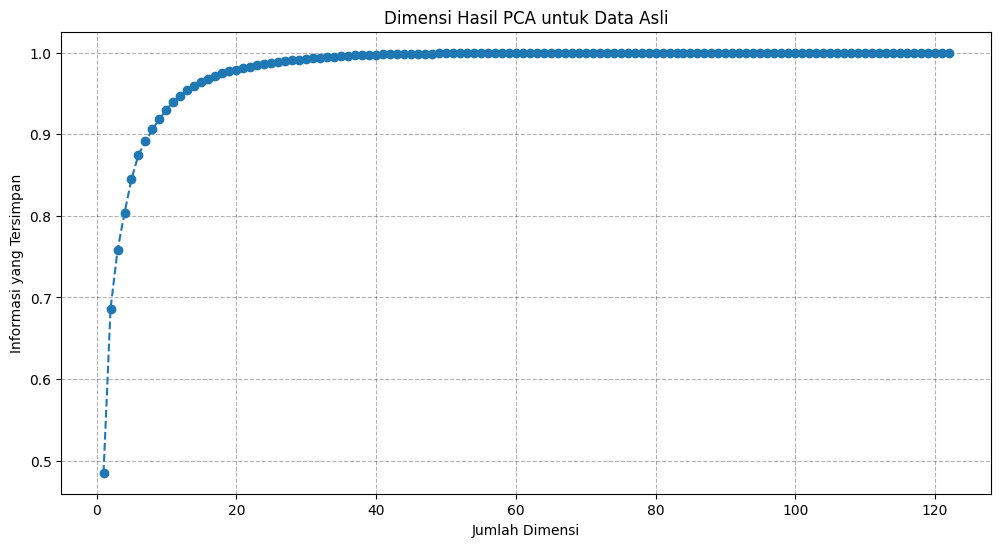

In [76]:
plt.figure(figsize=(12, 6))
plt.plot(range(1, len(explained_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.title("Dimensi Hasil PCA untuk Data Asli")
plt.grid(linestyle='--', alpha=0.3, color='black')
plt.xlabel('Jumlah Dimensi')
plt.ylabel('Informasi yang Tersimpan')
plt.show()

In [ ]:
x_train_pca = transform(x_train_scaled, eigenvectors, n_components=10)
x_test_pca = transform(x_test_scaled, eigenvectors, n_components=10)

In [78]:
x_train_pca.shape

(32803, 10)

In [79]:
knn = KNearestNeighbours(n_neighbours=3, metric='euclidean')
knn.fit(x_train_pca, y_train)
y_pred = knn.predict(x_test_pca)

In [80]:
acc = np.mean(y_pred == y_test)
print(f'Akurasi Model KNearestNeighbours {acc}')

Akurasi Model KNearestNeighbours 0.8871519296531509


In [81]:
def classification_report(y_test, y_pred, average=None):
    labels = np.unique(np.concatenate((y_test, y_pred)))
    report = {}
    for label in labels:
        tp = sum((y_test[i] == label) and (y_pred[i] == label) for i in range(len(y_test)))
        tn = sum((y_test[i] != label) and (y_pred[i] != label) for i in range(len(y_test)))
        fp = sum((y_test[i] != label) and (y_pred[i] == label) for i in range(len(y_test)))
        fn = sum((y_test[i] == label) and (y_pred[i] != label) for i in range(len(y_test)))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        support = sum(y == label for y in y_test)

        report[label] = {
            'precision': precision,
            'recall': recall,
            'f1_score': f1_score,
            'support': support
        }

    if average == 'macro':
        avg_precision = sum(report[label]['precision'] for label in labels) / len(labels)
        avg_recall = sum(report[label]['recall'] for label in labels) / len(labels)
        avg_f1_score = sum(report[label]['f1_score'] for label in labels) / len(labels)
        avg_support = sum(report[label]['support'] for label in labels)

        report['macro avg'] = {
            'precision': avg_precision,
            'recall': avg_recall,
            'f1_score': avg_f1_score,
            'support': avg_support
        }

    return report

In [82]:
report_dummy = classification_report(y_pred, y_test, average='macro')

In [83]:
def print_report(report):
    print(f'{'Kelas':<15} {'Precision':<15} {'Recall':<15} {'F1-Score':<15} {'Support':<15}')
    print('='*70)
    for label, metric in report.items():
        print(f'{label:<15} {metric['precision']:<15.2f} {metric['recall']:<15.2f} {metric['f1_score']:<15.2f} {metric['support']:<15}')

In [84]:
print_report(report_dummy)

Kelas           Precision       Recall          F1-Score        Support        
0               0.94            0.87            0.91            355            
1               0.97            0.91            0.94            353            
2               0.92            0.84            0.88            368            
3               0.80            0.84            0.82            318            
4               0.91            0.82            0.86            370            
5               0.93            0.93            0.93            339            
6               0.85            0.88            0.87            317            
7               0.96            0.95            0.96            342            
8               0.86            0.82            0.84            318            
9               0.86            0.87            0.87            328            
10              0.94            0.94            0.94            329            
11              0.85            0.85    

In [94]:
char_map

{'A': 0,
 'B': 1,
 'C': 2,
 'D': 3,
 'E': 4,
 'F': 5,
 'G': 6,
 'H': 7,
 'I': 8,
 'K': 9,
 'L': 10,
 'M': 11,
 'N': 12,
 'O': 13,
 'P': 14,
 'Q': 15,
 'R': 16,
 'S': 17,
 'T': 18,
 'U': 19,
 'V': 20,
 'W': 21,
 'X': 22,
 'Y': 23}

---

In [121]:
all_fingers = df.copy(deep=True)
all_fingers

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,18xy*,18xy/,19xy+,19xy-,19xy*,19xy/,20xy+,20xy-,20xy*,20xy/
1,459.426,468.581,347.614,599.550,273.522,486.969,262.374,354.810,248.102,248.011,...,201640.516761,1.773752,970.518,148.802,229940.788286,1.362174,1003.402,92.926,249545.083037,1.204126
2,444.194,468.581,326.598,616.910,253.226,497.914,243.082,361.876,239.491,259.676,...,196435.146566,1.639990,950.500,116.812,222451.301669,1.280230,975.094,73.472,236352.543518,1.162977
3,443.780,468.581,324.970,607.825,252.818,487.201,244.345,356.561,243.655,256.638,...,196704.580336,1.711388,952.482,129.892,222587.507170,1.315812,973.839,82.285,235397.894179,1.184588
4,452.860,468.581,340.436,595.407,272.323,487.497,254.365,357.569,231.482,241.993,...,196282.343764,1.722651,961.603,141.147,226189.463506,1.344070,996.510,96.638,245923.319269,1.214782
5,457.552,468.581,335.113,436.147,264.734,510.101,253.082,378.250,236.840,269.307,...,203328.803186,1.659087,969.109,127.335,230739.512919,1.302540,995.168,83.692,245838.749345,1.183641
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8208,454.776,476.377,403.617,408.764,391.925,343.421,389.176,279.748,367.133,241.514,...,187706.419206,1.778590,895.034,295.222,178482.457974,1.984382,898.216,340.342,172739.826429,2.220139
8209,449.620,471.150,393.538,421.391,377.734,355.225,367.321,289.840,339.901,244.889,...,178491.822396,1.725622,868.246,280.400,168806.739135,1.953991,868.014,328.870,161323.206830,2.219971
8210,449.519,465.264,394.832,419.211,374.325,353.492,359.242,291.124,329.151,246.300,...,171850.707202,1.758502,851.740,290.802,160223.806105,2.036842,845.786,347.518,148646.299374,2.394904
8211,450.871,475.178,392.631,427.684,372.055,363.563,357.538,299.618,330.009,252.363,...,178451.954705,1.687284,862.061,268.661,167742.608706,1.905497,855.227,318.723,157457.217706,2.188148


In [ ]:
all_fingers.drop(columns='char', inplace=True)

In [123]:
new_data = pd.DataFrame([all_fingers.mean()])
new_data

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,18xy*,18xy/,19xy+,19xy-,19xy*,19xy/,20xy+,20xy-,20xy*,20xy/
0,451.107506,473.126376,427.349996,443.755739,423.505291,399.375609,439.276048,357.190837,452.991081,328.188008,...,191026.607743,1.607691,885.850502,171.223023,190201.474935,1.584557,886.075975,156.232427,190769.760635,1.576185


In [124]:
new_data_scaled = (new_data - min_val) / denominator
new_data_scaled

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,18xy*,18xy/,19xy+,19xy-,19xy*,19xy/,20xy+,20xy-,20xy*,20xy/
0,0.499561,0.502015,0.49636,0.504328,0.49303,0.47491,0.480175,0.49912,0.51809,0.501449,...,0.368377,0.104196,0.512984,0.51429,0.363072,0.144888,0.484845,0.461051,0.32934,0.089579


In [125]:
new_data_pca = transform(new_data_scaled, eigenvectors, n_components=10)

In [126]:
knn.predict(new_data_pca)

array([16])

In [127]:
k = 3
for i, new_point in enumerate(new_data_pca):
    distances = np.sqrt(np.sum((x_test_pca - new_point) ** 2, axis=1))
    print(f'3 jarak terdekat : {np.sort(distances)[:k]}')
    k_nearest = np.argsort(distances)[:k]
    print(f'3 Indeks terdekat : {k_nearest}')

3 jarak terdekat : [0.24749509+0.j 0.2821301 +0.j 0.29245013+0.j]
3 Indeks terdekat : [2842 7560 6337]


In [128]:
print(y_test[[2842, 7560, 6337]])

[ 8 22 18]


**`Karena hasil prediksinya tidak akurat, kami mencoba di file lain 30 Features`**